# STEP 4 – 강판 결함 데이터 전처리 최종 고도화
## 의미론적 중복 검증 + 이상치 심층 진단 + 손실 없는 강건 전처리

# STEP 4 – 강판 결함 유형 분류: 데이터 전처리 (실측 EDA 연계 고도화)

**프로젝트:** Steel Plates Faults | **입력:** 27개 측정 변수 | **정답:** 7개 결함 유형 | **분할:** Train 70% / Valid 15% / Test 15%

> **자료 계보:** `04_강판 결함_필수 전처리(2).ipynb`의 필수 7단계 순서를 유지하고, `04_STEP3_EDA_실측분석_보고서완성(1).ipynb` 및 `02_eda_detailed(1).py`에서 확인한 실측 EDA 결과를 전처리 의사결정에 반영함. 아래의 수치들은 첨부된 실제 원본으로 재검산하며, 실행 환경에서 데이터가 바뀌면 자동으로 결과를 새로 계산한다.

| 순서 | 절차 | EDA 기반 고도화 포인트 |
|:--:|---|---|
| 0 | 실행 환경 및 경로 | 업로드된 파일명 `(2)`, 공백 포함 CSV 자동 인식, 실행 버전 기록 |
| 1 | 원본 로딩 | 원시 `.NNA`와 CSV의 동일성 검증 및 원본 해시 보존 |
| 2 | 데이터 구조·무결성 | 34열(27+7), 원-핫 정답, 좌표·면적·밝기·강종 논리 검사 |
| 3 | 중복 검사·처리 | 완전 중복과 입력 동일·정답 상충 구별; 자동 오류 은폐 금지 |
| 4 | Train/Valid/Test 층화 분할 | STEP 3과 동일한 70/15/15, `random_state=42`; 클래스 분포 점검 |
| 4-A | **EDA→전처리 의사결정** | 왜도·IQR 이상값·강한 상관관계를 **Train에서만** 진단 |
| 5 | 결측치 처리 | Train 중앙값/최빈값으로만 `fit`; 결측 0건이어도 재사용 가능 |
| 6 | 스케일링 | 연속형 25개 표준화, 강종 이진 2개는 0/1 유지 |
| 7 | 원-핫 인코딩 | 현재 추가 문자열 0개 → 중복 인코딩하지 않음; 새 범주에는 대응 |
| 8 | 품질 검증·저장 | 입력·정답 분리, 집합 간 행 중복 점검, 재사용 파이프라인·로그·CSV 저장 |

**누수 방지 원칙:** 원본 스키마·클래스 빈도 점검 외에 분포·변환·변수 선택에 쓰이는 통계는 Train에서만 계산한다. Valid/Test는 `transform`만 허용하며, 최종 Test 성능은 모델 확정 후 STEP 5 이후에서 평가한다.

## 0. 실행 안내·라이브러리 준비

VS Code에서 이 노트북을 열고 우측 상단 **커널 선택**에서 프로젝트 Python 환경을 선택한 뒤 **모두 실행**한다. 권장 설치 명령: `python -m pip install numpy pandas scikit-learn matplotlib joblib ipykernel nbformat` (VS Code 터미널). 다음 셀은 설치가 아니라 가져오기와 경로 지정이다.

**파일 경로:** 기본은 현재 노트북을 연 작업 폴더(`Path.cwd()`). 실제 파일이 다른 경로에 있다면 `DATA_DIR = Path(r"C:\\...\\프로젝트폴더")`만 수정한다. 첨부된 `(2)` 파일 이름도 지원한다.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
TRAIN_RATIO, VALID_RATIO, TEST_RATIO = 0.70, 0.15, 0.15
DATA_DIR = Path.cwd()  # 필요할 때 프로젝트 데이터 폴더 경로로 변경
OUT_DIR = DATA_DIR / "outputs_preprocessing"
OUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

FAULT_COLS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains", "Dirtiness", "Bumps", "Other_Faults"]
BINARY_STEEL_COLS = ["TypeOfSteel_A300", "TypeOfSteel_A400"]

print("분석 폴더:", DATA_DIR.resolve())
print("저장 폴더:", OUT_DIR.resolve())
print("패키지 버전:", {"python": platform.python_version(), "pandas": pd.__version__,
                    "numpy": np.__version__, "sklearn": sklearn.__version__})

분석 폴더: C:\Users\sgr10\Desktop\steel_fault_project
저장 폴더: C:\Users\sgr10\Desktop\steel_fault_project\outputs_preprocessing
패키지 버전: {'python': '3.14.4', 'pandas': '3.0.6', 'numpy': '2.5.4', 'sklearn': '1.9.1'}


## 1. 데이터 로딩 및 원본 일치성 검증

`Faults.NNA`는 **헤더가 없는 공백 구분 원시 데이터**이며, `Faults27x7_var`는 **34개 열 이름**이다. `steel_plates_faults.csv`는 두 파일을 결합한 파생 CSV이다. CSV가 있으면 우선 읽고, 원시 데이터도 있으면 **셀별 동등성**을 추가 검증한다. 원본 파일은 덮어쓰지 않는다.

다른 팀원 컴퓨터에서 파일명이 달라졌더라도 후보 목록에서 탐색하며, 원본 파일이 누락되었으면 오류와 해결 경로를 출력한다.

In [2]:
def find_existing(base, filenames):
    return next((base / name for name in filenames if (base / name).is_file()), None)

def file_sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

csv_path = find_existing(DATA_DIR, [
    "steel_plates_faults.csv", "steel_plates_faults(2).csv",
    "steel_plates_faults 0.csv", "steel_plates_faults(1).csv",
])
names_path = find_existing(DATA_DIR, ["Faults27x7_var", "Faults27x7_var(2)", "Faults27x7_var(1)"])
raw_path = find_existing(DATA_DIR, ["Faults.NNA", "Faults(2).NNA", "Faults(1).NNA"])

raw_from_nna = None
if names_path is not None and raw_path is not None:
    names = [line.strip() for line in names_path.read_text(encoding="utf-8-sig").splitlines() if line.strip()]
    if len(names) != 34 or len(names) != len(set(names)):
        raise ValueError(f"원시 파일 열 이름이 34개 고유값이어야 합니다: {len(names)}")
    raw_from_nna = pd.read_csv(raw_path, sep=r"\s+", header=None, names=names)

if csv_path is not None:
    df_raw = pd.read_csv(csv_path, encoding="utf-8-sig")
    source_path = csv_path
    print("CSV 원본 선택:", csv_path.name)
    if raw_from_nna is not None:
        pd.testing.assert_frame_equal(df_raw, raw_from_nna, check_dtype=True, check_exact=True)
        print("[통과] 제공된 CSV와 NNA+열 이름 파일의 1,941행 전체 값이 동일함")
elif raw_from_nna is not None:
    df_raw = raw_from_nna
    source_path = raw_path
    print("NNA 원본 선택:", raw_path.name, "+", names_path.name)
else:
    raise FileNotFoundError(f"데이터 파일 없음: {DATA_DIR.resolve()}에 CSV 또는 NNA+열 이름 파일을 넣으세요.")

SOURCE_HASH_BEFORE = file_sha256(source_path)
print("원본 shape:", df_raw.shape)
print("원본 SHA-256:", SOURCE_HASH_BEFORE)
display(df_raw.head(3))

CSV 원본 선택: steel_plates_faults.csv
[통과] 제공된 CSV와 NNA+열 이름 파일의 1,941행 전체 값이 동일함
원본 shape: (1941, 34)
원본 SHA-256: d85b45f6c09119926bf5abb7192d7bfd113e8e3821778a3e7b6f0ff0a5bb2122


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,1687,1,0,80,0.0498,0.2415,0.1818,0.0047,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,1687,1,0,80,0.7647,0.3793,0.2069,0.0036,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,1623,1,0,100,0.9710,0.3426,0.3333,0.0037,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0


## 2. 데이터 크기·정답 형태·물리적 무결성 검증

**예상 구조:** 1,941행 × 34열(설명변수 27열 + 정답 원-핫 7열). `Pastry`, `Z_Scratch`, `K_Scatch`, `Stains`, `Dirtiness`, `Bumps`, `Other_Faults`는 **정답**이다. 모델의 `X`에 이 7개 열이나 합성 정답 열 `Fault`를 포함하면 정답을 미리 보여주는 **타깃 누수**가 발생한다.

**데이터 품질 검사:** 결측·무한대, 숫자형, 7개 정답 이진값/행별 합계 1, 강종 A300/A400의 이진 상보성, 좌표 범위, 양의 면적·둘레·두께, 최소 밝기 ≤ 최대 밝기를 확인한다. 이상이 생기면 **임의로 교정·삭제하지 않고 오류를 알려 원자료를 확인**한다. 강판의 특성값이 크다는 이유만으로 측정 오류로 판단하지 않는다.

In [3]:
if df_raw.columns.duplicated().any():
    raise ValueError("열 이름 중복이 있습니다.")
if any(c not in df_raw.columns for c in FAULT_COLS):
    raise ValueError("결함 정답 7개 열 중 누락된 항목이 있습니다.")
FEATURE_COLS = [c for c in df_raw.columns if c not in FAULT_COLS]
if len(FEATURE_COLS) != 27 or df_raw.shape[1] != 34:
    raise ValueError(f"예상 구조는 27개 설명변수+7개 정답변수입니다. 현재 {df_raw.shape}")
if not all(pd.api.types.is_numeric_dtype(df_raw[c]) for c in df_raw.columns):
    raise ValueError("원본 열 중 숫자로 읽히지 않은 열이 있습니다. 파일 형식을 점검하세요.")

numeric_arr = df_raw.to_numpy(dtype=float)
inf_total = int(np.isinf(numeric_arr).sum())
na_total = int(df_raw.isna().sum().sum())
label_ok = bool(df_raw[FAULT_COLS].isin([0, 1]).all().all() and
                df_raw[FAULT_COLS].sum(axis=1).eq(1).all())
checks = {
    "non_finite_infinite_cells": inf_total,
    "missing_cells": na_total,
    "onehot_invalid_rows": int((~df_raw[FAULT_COLS].isin([0, 1]).all(axis=1) |
                                 ~df_raw[FAULT_COLS].sum(axis=1).eq(1)).sum()),
    "steel_binary_invalid_rows": int((~df_raw[BINARY_STEEL_COLS].isin([0, 1]).all(axis=1) |
                                      ~df_raw[BINARY_STEEL_COLS].sum(axis=1).eq(1)).sum()),
    "x_max_below_x_min": int((df_raw["X_Maximum"] < df_raw["X_Minimum"]).sum()),
    "y_max_below_y_min": int((df_raw["Y_Maximum"] < df_raw["Y_Minimum"]).sum()),
    "nonpositive_area": int((df_raw["Pixels_Areas"] <= 0).sum()),
    "nonpositive_x_perimeter": int((df_raw["X_Perimeter"] <= 0).sum()),
    "nonpositive_y_perimeter": int((df_raw["Y_Perimeter"] <= 0).sum()),
    "nonpositive_thickness": int((df_raw["Steel_Plate_Thickness"] <= 0).sum()),
    "min_brightness_gt_max": int((df_raw["Minimum_of_Luminosity"] > df_raw["Maximum_of_Luminosity"]).sum()),
}
quality_table = pd.DataFrame({"검사항목": list(checks.keys()), "발견 건수": list(checks.values())})
display(quality_table)
if not label_ok or inf_total:
    raise ValueError("정답 원-핫 형식 오류 또는 무한대가 있습니다. 원본을 검토해야 합니다.")
physical_issues = {k: v for k, v in checks.items() if k not in ("missing_cells", "non_finite_infinite_cells") and v}
if physical_issues:
    raise ValueError(f"원자료 무결성 검사를 통과하지 못했습니다: {physical_issues}")

df = df_raw.copy()
df["Fault"] = df[FAULT_COLS].idxmax(axis=1)
class_total = df["Fault"].value_counts().reindex(FAULT_COLS, fill_value=0)
class_overview = pd.DataFrame({"Count": class_total, "Percent": (100 * class_total / len(df)).round(2)})
display(class_overview)
print(f"데이터: {len(df):,}건 / {len(FEATURE_COLS)}개 입력 / {len(FAULT_COLS)}개 클래스")

,검사항목,발견 건수
0,non_finite_infinite_cells,0
1,missing_cells,0
2,onehot_invalid_rows,0
3,steel_binary_invalid_rows,0
4,x_max_below_x_min,0
5,y_max_below_y_min,0
6,nonpositive_area,0
7,nonpositive_x_perimeter,0
8,nonpositive_y_perimeter,0
9,nonpositive_thickness,0


,Count,Percent
Fault,,
Pastry,158,8.14
Z_Scratch,190,9.79
K_Scatch,391,20.14
Stains,72,3.71
Dirtiness,55,2.83
Bumps,402,20.71
Other_Faults,673,34.67


데이터: 1,941건 / 27개 입력 / 7개 클래스


## 3. 완전 중복·동일 입력의 정답 충돌 검사

- **완전 중복:** 27개 입력값과 `Fault`가 모두 동일한 추가 행 → 분할 전에 중복 제거하여 Train/Test 사이의 동일 관측치 누수 방지.
- **정답 충돌:** 입력값 27개가 완전히 같은데 서로 다른 `Fault`가 부여된 그룹 → 자동 다수결 또는 제거는 오분류 원인을 은폐할 수 있으므로 **오류로 중단**.
- **원본 실측:** 완전 중복 0건, 정답 충돌 0그룹. 따라서 1,941건 유지가 맞다. 다른 버전의 데이터에서는 다시 검사한다.

**중요:** 유사한 값이나 상관관계가 높은 행은 완전 중복으로 제거하지 않는다.

In [4]:
full_dup_count = int(df.duplicated(subset=FEATURE_COLS + ["Fault"]).sum())
same_inputs = df.duplicated(subset=FEATURE_COLS, keep=False)
if same_inputs.any():
    label_variants = df.loc[same_inputs].groupby(FEATURE_COLS, dropna=False)["Fault"].nunique()
    conflict_groups = int((label_variants > 1).sum())
else:
    conflict_groups = 0
print("완전 중복:", full_dup_count, "건")
print("입력 동일·정답 충돌:", conflict_groups, "그룹")
if conflict_groups:
    raise ValueError("같은 측정값에 서로 다른 결함 유형이 존재합니다. 원본 확인 전 학습 금지")
df_clean = df.drop_duplicates(subset=FEATURE_COLS + ["Fault"]).copy()
print("중복 제거 후:", len(df_clean), "건 (제거", len(df) - len(df_clean), "건)")
assert not df_clean.duplicated(subset=FEATURE_COLS + ["Fault"]).any()

완전 중복: 0 건
입력 동일·정답 충돌: 0 그룹
중복 제거 후: 1941 건 (제거 0 건)


## 4. 학습·검증·테스트 데이터 분할: 70% / 15% / 15%

**왜 층화(`stratify`)가 필요한가?** EDA에서 가장 많은 `Other_Faults` 673건(34.67%)과 가장 적은 `Dirtiness` 55건(2.83%)의 최대/최소 비율이 **12.24배**였다. 단순 무작위 분리 시 소수 유형이 한 집합에서 지나치게 적어질 수 있으므로, 7개 결함 유형의 비율을 가급적 유지한다.

1. 전체에서 **Test 15%** 별도 분리(최종 평가 전까지 모델 선택에 사용 금지)
2. 나머지 85%에서 전체의 15%에 해당하는 양만큼 **Valid** 분리: `0.15 / 0.85`
3. 나머지 **Train 70%**

기존 STEP 3 상세 EDA와 **같은 2단계 분리 순서·seed=42**를 사용하므로 Train 기반 수치가 일치한다. 분할은 생산 순서를 따르지 않는 랜덤 분할이며, 원본에 시간·라인·코일 그룹 구분 정보가 확인되지 않으므로 실제 현장 일반화 성능까지 보장하지 않는다.

In [5]:
train_valid_df, test_df = train_test_split(
    df_clean, test_size=TEST_RATIO, random_state=SEED, stratify=df_clean["Fault"]
)
train_df, valid_df = train_test_split(
    train_valid_df, test_size=VALID_RATIO / (TRAIN_RATIO + VALID_RATIO),
    random_state=SEED, stratify=train_valid_df["Fault"]
)
parts = {"Train": train_df, "Valid": valid_df, "Test": test_df}
assert sum(len(v) for v in parts.values()) == len(df_clean)
assert not (set(train_df.index) & set(valid_df.index) or
            set(train_df.index) & set(test_df.index) or
            set(valid_df.index) & set(test_df.index))

split_counts = pd.DataFrame({"All": df_clean["Fault"].value_counts(),
                             **{name: chunk["Fault"].value_counts() for name, chunk in parts.items()}})
split_counts = split_counts.reindex(FAULT_COLS).fillna(0).astype(int)
split_pct = (split_counts.div(split_counts.sum(axis=0), axis=1) * 100).round(2)
print("분할 수:", {k: len(v) for k, v in parts.items()})
print("\n결함 유형별 분할 건수:")
display(split_counts)
print("\n각 집합의 결함 유형 비율(%):")
display(split_pct)
assert (split_counts[["Train", "Valid", "Test"]] > 0).all().all()

X_train, y_train = train_df[FEATURE_COLS].copy(), train_df["Fault"].copy()
X_valid, y_valid = valid_df[FEATURE_COLS].copy(), valid_df["Fault"].copy()
X_test, y_test = test_df[FEATURE_COLS].copy(), test_df["Fault"].copy()
assert not any(c in X_train.columns for c in FAULT_COLS + ["Fault"])

분할 수: {'Train': 1358, 'Valid': 291, 'Test': 292}

결함 유형별 분할 건수:


,All,Train,Valid,Test
Fault,,,,
Pastry,158,110,24,24
Z_Scratch,190,133,28,29
K_Scatch,391,273,59,59
Stains,72,50,11,11
Dirtiness,55,39,8,8
Bumps,402,282,60,60
Other_Faults,673,471,101,101



각 집합의 결함 유형 비율(%):


,All,Train,Valid,Test
Fault,,,,
Pastry,8.14,8.10,8.25,8.22
Z_Scratch,9.79,9.79,9.62,9.93
K_Scatch,20.14,20.10,20.27,20.21
Stains,3.71,3.68,3.78,3.77
Dirtiness,2.83,2.87,2.75,2.74
Bumps,20.71,20.77,20.62,20.55
Other_Faults,34.67,34.68,34.71,34.59


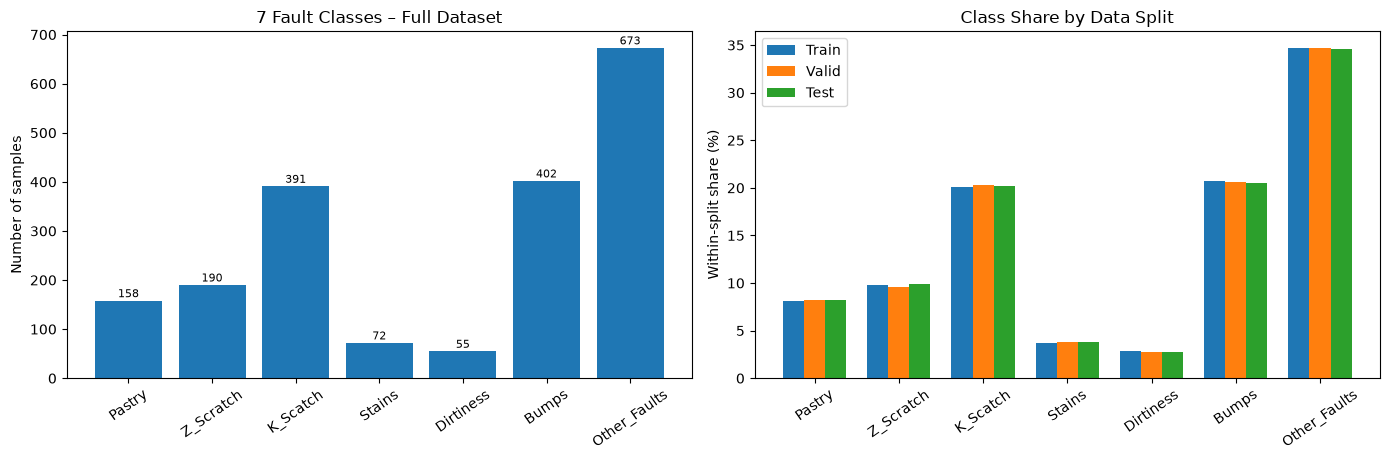

In [6]:
# 시각화 ① 전체 원본의 결함 불균형(전체 분포 설명용; 변환 기준 학습에는 사용하지 않음)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.7))
all_counts = split_counts["All"]
axes[0].bar(all_counts.index, all_counts.values)
axes[0].set_title("7 Fault Classes – Full Dataset")
axes[0].set_ylabel("Number of samples")
axes[0].tick_params(axis="x", rotation=35)
for i, count in enumerate(all_counts):
    axes[0].text(i, count + 7, str(count), ha="center", fontsize=8)
order = np.arange(len(FAULT_COLS))
width = 0.25
for j, name in enumerate(["Train", "Valid", "Test"]):
    axes[1].bar(order + (j-1)*width, split_pct[name].to_numpy(), width, label=name)
axes[1].set_xticks(order, FAULT_COLS, rotation=35)
axes[1].set_title("Class Share by Data Split")
axes[1].set_ylabel("Within-split share (%)")
axes[1].legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "01_class_distribution_and_split.png", dpi=160, bbox_inches="tight")
plt.show()

## 4-B. 의미론적 중복·유사 관측치·분할 간 겹침 추가 검증

**앞의 ‘완전 중복 0건’이 의미론적 중복 0건이라는 뜻은 아니다.** 동일한 실제 결함이 위치·밝기·경계 등의 측정 오차 때문에 약간 다른 행으로 기록되었을 수 있으므로 별도 심화 검사를 수행한다.

- **정확한 중복**: 원본 27개 특성과 `Fault` 전체가 정확히 같은 행. 0건.
- **핵심 측정값 일치**: 면적·둘레·밝기 합계/범위·두께·강종 8개 값이 모두 같은 쌍. 1쌍.
- **유사 관측치 후보**: 같은 강종·두께, 면적·둘레의 상대차 ≤2%, 최솟값/최댓값 밝기 차 각각 ≤5인 쌍. **후보 검색용 임의 기준이며 중복 확정이 아니다.**
- **좌표 영역 중첩**: 경계상자 Intersection over Union(IoU) ≥0.5인 쌍을 별도로 확인. 좌표가 다른 코일에서 반복될 수 있으므로 겹친다고 무조건 동일 관측치는 아니다.
- **분할 간 위험**: 같은 원본 행이나 정확히 동일한 27개 특성의 교차는 없으나, 유사 관측치가 Train/Valid/Test에 걸쳐 있을 수 있어 원본 이미지·강판 ID 확인이 바람직하다.

**전처리 정책:** 의미론적 중복 후보를 자동으로 제거하거나 임의로 합치지 않는다. 이진 강종 열의 상보 관계, 로그 변수의 파생 관계는 *행 중복*이 아닌 *특성 중복 정보*로 별도 기록한다.

In [7]:
# -*- coding: utf-8 -*-
"""STEP 4 supplementary audit: exact, partial, near, geometric duplicate candidates.

Does not remove any rows or alter the existing Train/Valid/Test split.
Run: python STEP4_semantic_duplicate_audit.py
Input: steel_plates_faults.csv, outputs_preprocessing/10_split_assignment_audit.csv
"""
from pathlib import Path
import numpy as np
import pandas as pd

FAULT_COLS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains", "Dirtiness", "Bumps", "Other_Faults"]
CORE_8 = ["Pixels_Areas", "X_Perimeter", "Y_Perimeter", "Sum_of_Luminosity",
          "Minimum_of_Luminosity", "Maximum_of_Luminosity", "Steel_Plate_Thickness", "TypeOfSteel_A300"]


def run_audit(df: pd.DataFrame, split_map: pd.Series, out_dir: Path):
    """Use original row indices for split assignment; produce candidate pair CSVs and report."""
    out_dir.mkdir(parents=True, exist_ok=True)
    d = df.copy()
    if "Fault" not in d:
        d["Fault"] = d[FAULT_COLS].idxmax(axis=1)
    feature_cols = [c for c in d.columns if c not in FAULT_COLS + ["Fault"]]
    if len(feature_cols) != 27:
        raise ValueError(f"Expected 27 features, got {len(feature_cols)}")
    n = len(d)
    if not d.index.is_unique or split_map.reindex(d.index).isna().any():
        raise ValueError("Missing or duplicate original row indices in split assignment")
    splits = split_map.reindex(d.index).astype(str).to_numpy()
    faults = d.Fault.to_numpy()
    i, j = np.triu_indices(n, k=1)

    def v(col):
        return d[col].to_numpy(dtype=float)

    def reldiff(col):
        arr = v(col)
        return np.abs(arr[i] - arr[j]) / np.maximum(1, np.maximum(np.abs(arr[i]), np.abs(arr[j])))

    def abdiff(col):
        arr = v(col)
        return np.abs(arr[i] - arr[j])

    # Conservative, documented *screening rule*, not a proof of duplicate identity.
    near_mask = (
        (v("TypeOfSteel_A300")[i] == v("TypeOfSteel_A300")[j])
        & (v("Steel_Plate_Thickness")[i] == v("Steel_Plate_Thickness")[j])
        & (reldiff("Pixels_Areas") <= 0.02)
        & (reldiff("X_Perimeter") <= 0.02)
        & (reldiff("Y_Perimeter") <= 0.02)
        & (abdiff("Minimum_of_Luminosity") <= 5)
        & (abdiff("Maximum_of_Luminosity") <= 5)
    )
    # Bounding-box IoU from positions only. This is not a reliable identity test
    # across steel coils/plates if coordinates reset between acquisitions.
    left = np.maximum(v("X_Minimum")[i], v("X_Minimum")[j])
    right = np.minimum(v("X_Maximum")[i], v("X_Maximum")[j])
    bottom = np.maximum(v("Y_Minimum")[i], v("Y_Minimum")[j])
    top = np.minimum(v("Y_Maximum")[i], v("Y_Maximum")[j])
    intersection = np.maximum(right - left, 0) * np.maximum(top - bottom, 0)
    box_area = np.maximum(v("X_Maximum") - v("X_Minimum"), 0) * np.maximum(v("Y_Maximum") - v("Y_Minimum"), 0)
    union = box_area[i] + box_area[j] - intersection
    iou = np.divide(intersection, union, out=np.zeros_like(intersection), where=union > 0)
    overlap_mask = iou >= 0.5

    def pair_table(mask):
        p = np.where(mask)[0]
        out = pd.DataFrame({
            "row_a_1based": d.index.to_numpy()[i[p]] + 1,
            "row_b_1based": d.index.to_numpy()[j[p]] + 1,
            "split_a": splits[i[p]], "split_b": splits[j[p]],
            "class_a": faults[i[p]], "class_b": faults[j[p]],
            "same_class": faults[i[p]] == faults[j[p]],
            "cross_split": splits[i[p]] != splits[j[p]],
            "area_relative_diff": reldiff("Pixels_Areas")[p],
            "x_perimeter_relative_diff": reldiff("X_Perimeter")[p],
            "y_perimeter_relative_diff": reldiff("Y_Perimeter")[p],
            "min_luminosity_abs_diff": abdiff("Minimum_of_Luminosity")[p],
            "max_luminosity_abs_diff": abdiff("Maximum_of_Luminosity")[p],
            "box_iou": iou[p],
        })
        return out

    # Exactly matching fundamental measurements while allowing other fields to differ
    core_group = d.duplicated(CORE_8, keep=False)
    core_pairs = pair_table(np.zeros_like(near_mask, dtype=bool))
    if core_group.any():
        groups = d.loc[core_group].groupby(CORE_8, dropna=False, sort=False)
        row_pairs = []
        for _, group in groups:
            idx = group.index.to_numpy()
            for k in range(len(idx)):
                for z in range(k + 1, len(idx)):
                    row_pairs.append((int(idx[k]), int(idx[z])))
        if row_pairs:
            core_pair_mask = np.zeros_like(near_mask)
            # Translate original index -> positional index only once
            pos = {int(index): p for p, index in enumerate(d.index)}
            selected = {(min(pos[a], pos[b]), max(pos[a], pos[b])) for a, b in row_pairs}
            core_pair_mask = np.fromiter(((int(a), int(b)) in selected for a, b in zip(i, j)), bool, count=len(i))
            core_pairs = pair_table(core_pair_mask)

    near_pairs = pair_table(near_mask)
    overlap_pairs = pair_table(overlap_mask).sort_values("box_iou", ascending=False)
    core_pairs.to_csv(out_dir / "11_core_measurement_matching_pairs.csv", index=False, encoding="utf-8-sig")
    near_pairs.to_csv(out_dir / "12_near_duplicate_candidate_pairs.csv", index=False, encoding="utf-8-sig")
    overlap_pairs.to_csv(out_dir / "13_overlapping_bounding_boxes.csv", index=False, encoding="utf-8-sig")

    def n_dup(cols):
        return int(d.duplicated(cols).sum())

    summary = {
        "original_rows": n,
        "full_duplicates": n_dup(feature_cols + ["Fault"]),
        "input_exact_duplicates": n_dup(feature_cols),
        "input_exact_duplicates_ignoring_XY": n_dup([c for c in feature_cols if c not in ["X_Minimum", "X_Maximum", "Y_Minimum", "Y_Maximum"]]),
        "core8_matching_pairs": len(core_pairs),
        "near_candidate_pairs": len(near_pairs),
        "near_candidate_involved_rows": len(set(near_pairs.row_a_1based) | set(near_pairs.row_b_1based)),
        "near_candidate_cross_split_pairs": int(near_pairs.cross_split.sum()),
        "near_candidate_different_label_pairs": int((~near_pairs.same_class).sum()),
        "bbox_iou_ge_0_5_pairs": len(overlap_pairs),
        "group_identifier_available": False,
    }
    summary_df = pd.DataFrame([summary])
    summary_df.to_csv(out_dir / "14_semantic_duplicate_audit_summary.csv", index=False, encoding="utf-8-sig")

    transition = {"Train-Train": 0, "Train-Valid": 0, "Train-Test": 0, "Valid-Valid": 0, "Valid-Test": 0, "Test-Test": 0}
    order = {"Train": 0, "Valid": 1, "Test": 2}
    for _, row in near_pairs.iterrows():
        ss = sorted([row.split_a, row.split_b], key=lambda a: order.get(a, 9))
        transition["-".join(ss)] = transition.get("-".join(ss), 0) + 1
    trans_df = pd.DataFrame([{"split_relationship": k, "candidate_pairs": v} for k, v in transition.items()])
    trans_df.to_csv(out_dir / "15_near_duplicate_pairs_by_split.csv", index=False, encoding="utf-8-sig")

    # Redundancy of *columns* is conceptually different from duplicate *rows*.
    derived = {
        "A300_plus_A400_equals_1": int((d["TypeOfSteel_A300"] + d["TypeOfSteel_A400"] == 1).sum()),
        "LogOfAreas_matches_log10_area_within_0.00011": int((np.abs(d["LogOfAreas"] - np.log10(d["Pixels_Areas"])) < .00011).sum()),
        "Log_X_matches_log10_width_within_0.00011": int((np.abs(d["Log_X_Index"] - np.log10(d["X_Maximum"] - d["X_Minimum"])) < .00011).sum()),
        "Log_Y_matches_log10_height_within_0.00011": int((np.abs(d["Log_Y_Index"] - np.log10(d["Y_Maximum"] - d["Y_Minimum"])) < .00011).sum()),
    }
    pd.DataFrame([derived]).to_csv(out_dir / "16_derived_feature_redundancy_checks.csv", index=False, encoding="utf-8-sig")

    lines = [
        "# STEP 4 – 의미론적 중복 의심 관측치 재검증 보고서", "",
        "> 이 문서는 원본 데이터를 삭제하거나 Train/Valid/Test를 재분할하지 않고, 추가 점검한 결과입니다.", "",
        f"- 전체 표본: **{n:,}건**",
        f"- 27개 입력+정답 완전 중복: **{summary['full_duplicates']}건**",
        f"- 27개 입력만 완전 일치: **{summary['input_exact_duplicates']}건**",
        f"- X/Y 위치 4개 열을 제외한 23개 입력 완전 일치: **{summary['input_exact_duplicates_ignoring_XY']}건**",
        f"- 핵심 측정값 8개가 완전히 같은 관측치: **{len(core_pairs)}쌍**",
        f"- 별도 허용오차 규칙으로 찾은 유사 관측치: **{len(near_pairs)}쌍** (관계된 행 {summary['near_candidate_involved_rows']}건)",
        f"- 그중 분할 집합이 서로 다른 후보: **{summary['near_candidate_cross_split_pairs']}쌍**",
        f"- 그중 결함 클래스가 다른 후보: **{summary['near_candidate_different_label_pairs']}쌍**",
        f"- 좌표 경계상자 IoU >= 0.5: **{len(overlap_pairs)}쌍**", "",
        "## 유사 관측치 탐색 조건 (연구자 정의, 확정 중복 기준 아님)", "",
        "동일 강종(A300 여부), 동일 두께, 결함 면적의 상대차 <= 2%, X 둘레 상대차 <= 2%, Y 둘레 상대차 <= 2%, 최솟값 밝기와 최댓값 밝기 차가 각각 <= 5인 두 관측치를 후보로 표시했다.",
        "상대차는 |a-b|/max(1, |a|, |b|)로 정의했다. 이 기준은 스크리닝을 위한 임의 허용오차로, 실제 중복이나 오표기를 판정하지 않는다.", "",
        "## 분할 간 후보", "",
        "| 분할 관계 | 후보 쌍 수 |", "|---|---:|",
    ]
    for k, value in transition.items():
        lines.append(f"| {k} | {value} |")
    lines += [
        "", "## 주요 사례", "",
        "- 원본 **1,776–1,777행**: Other_Faults, 27개 입력 특성 중 23개 값 동일, 경계상자 IoU 0.52, 두 행의 분할은 Test/Valid. 면적·둘레·밝기 합계 동일. 원본 이미지·코일 ID가 없어 같은 결함인지 확정 불가.",
        "- 원본 **530–679행**: K_Scatch, 경계상자 IoU 약 0.7265, 양쪽 모두 Train. 둘레·밝기·컨베이어 길이가 달라 같은 결함 여부를 알 수 없음.",
        "- 원본 **251–1409행**: 허용오차 기준상 유사하지만 정답 Z_Scratch/Other_Faults가 다르고 실제 좌표는 크게 다름. 이를 정답 충돌이나 오표기로 판정하지 않아야 함.", "",
        "## 중복 행과 중복 정보(변수)의 구별", "",
        f"- A300/A400 이진변수 합계가 1인 행: {derived['A300_plus_A400_equals_1']:,}/{n:,}건",
        f"- LogOfAreas ≈ log10(Pixels_Areas): {derived['LogOfAreas_matches_log10_area_within_0.00011']:,}/{n:,}건",
        f"- Log_X_Index ≈ log10(X_Maximum-X_Minimum): {derived['Log_X_matches_log10_width_within_0.00011']:,}/{n:,}건",
        f"- Log_Y_Index ≈ log10(Y_Maximum-Y_Minimum): {derived['Log_Y_matches_log10_height_within_0.00011']:,}/{n:,}건",
        "이는 변수 간 파생·중복 정보이며 동일한 *행*이라는 뜻은 아니다. EDA 이후 별도의 변수 선택 실험으로 평가할 수 있다.", "",
        "## 데이터 처리 결정", "",
        "1. **추가 삭제 0건**: 원본 이미지·강판 ID·코일/배치 정보가 없어 별개의 유사 결함인지 중복 채록인지 식별 불가.",
        "2. 현재 랜덤 층화 분할은 유사한 관측치의 Train/Valid/Test 동시 포함 가능성을 배제하지 못함. 완전 동일 27개 입력의 분할 교차는 없음.",
        "3. 가능하다면 코일/배치/이미지/생산시각 ID로 동일 결함 여부를 원천 확인한 뒤, 동일 원천 단위로 **Group 기반 분할**을 실시한다.",
        "4. 의심 쌍을 유사도만으로 결합하거나 정답을 통일하면 실제 다른 결함을 삭제·변경할 수 있으므로 금지한다.",
        "5. 보고서 문구는 '완전 중복 0건, 의미론적 중복 여부 미확정(후보 발견)'으로 기술한다.",
    ]
    (out_dir / "STEP4_의미론적중복_추가검증_보고서.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
    return summary, near_pairs, overlap_pairs, core_pairs



# 원본 행 번호를 보존한 분할 맵을 이용해 같은 결함일 가능성이 있는 관측치 탐색
split_map_semantic = pd.concat([
    pd.Series(name, index=chunk.index, name="split") for name, chunk in parts.items()
])
audit_summary, semantic_near_pairs, geometric_overlap_pairs, core_matching_pairs = run_audit(
    df_clean, split_map_semantic, OUT_DIR
)
print("[완전 중복]", audit_summary["full_duplicates"], "건")
print("[핵심 측정값 8개 일치]", audit_summary["core8_matching_pairs"], "쌍")
print("[유사 결함 후보]", audit_summary["near_candidate_pairs"], "쌍")
print("[유사 후보 중 서로 다른 분할에 위치]", audit_summary["near_candidate_cross_split_pairs"], "쌍")
print("[IoU 0.5 이상]", audit_summary["bbox_iou_ge_0_5_pairs"], "쌍")
print("[주의] 의미론적으로 동일한 실제 결함인지 확인하려면 이미지/생산 ID가 필요합니다. 후보를 삭제하지 않았습니다.")
print("\n핵심 측정값이 일치하는 의심 쌍:")
display(core_matching_pairs)
print("\n공간적으로 겹치는 의심 쌍:")
display(geometric_overlap_pairs)
print("\n유사 결함 후보 중 분할 간 공유된 사례(앞 12쌍):")
display(semantic_near_pairs.loc[semantic_near_pairs.cross_split].head(12))


[완전 중복] 0 건
[핵심 측정값 8개 일치] 1 쌍
[유사 결함 후보] 35 쌍
[유사 후보 중 서로 다른 분할에 위치] 12 쌍
[IoU 0.5 이상] 2 쌍
[주의] 의미론적으로 동일한 실제 결함인지 확인하려면 이미지/생산 ID가 필요합니다. 후보를 삭제하지 않았습니다.

핵심 측정값이 일치하는 의심 쌍:


,row_a_1based,row_b_1based,split_a,split_b,class_a,class_b,same_class,cross_split,area_relative_diff,x_perimeter_relative_diff,y_perimeter_relative_diff,min_luminosity_abs_diff,max_luminosity_abs_diff,box_iou
0,1776,1777,Test,Valid,Other_Faults,Other_Faults,True,True,0.0,0.0,0.0,0.0,0.0,0.52



공간적으로 겹치는 의심 쌍:


,row_a_1based,row_b_1based,split_a,split_b,class_a,class_b,same_class,cross_split,area_relative_diff,x_perimeter_relative_diff,y_perimeter_relative_diff,min_luminosity_abs_diff,max_luminosity_abs_diff,box_iou
0,530,679,Train,Train,K_Scatch,K_Scatch,True,False,0.040066,0.139108,0.203704,22.0,17.0,0.726479
1,1776,1777,Test,Valid,Other_Faults,Other_Faults,True,True,0.000000,0.000000,0.000000,0.0,0.0,0.520000



유사 결함 후보 중 분할 간 공유된 사례(앞 12쌍):


,row_a_1based,row_b_1based,split_a,split_b,class_a,class_b,same_class,cross_split,area_relative_diff,x_perimeter_relative_diff,y_perimeter_relative_diff,min_luminosity_abs_diff,max_luminosity_abs_diff,box_iou
1,255,271,Test,Train,Z_Scratch,Z_Scratch,True,True,0.000000,0.000000,0.000000,0.0,2.0,0.00
2,407,410,Valid,Train,K_Scatch,K_Scatch,True,True,0.006676,0.014963,0.003711,0.0,5.0,0.00
3,445,458,Train,Valid,K_Scatch,K_Scatch,True,True,0.007929,0.011401,0.008287,4.0,0.0,0.00
5,466,483,Valid,Train,K_Scatch,K_Scatch,True,True,0.006741,0.016181,0.015748,2.0,0.0,0.00
6,466,487,Valid,Train,K_Scatch,K_Scatch,True,True,0.005872,0.008026,0.015504,2.0,2.0,0.00
10,506,570,Train,Test,K_Scatch,K_Scatch,True,True,0.000000,0.009259,0.008403,2.0,1.0,0.00
11,571,578,Test,Train,K_Scatch,K_Scatch,True,True,0.014981,0.009662,0.000000,3.0,0.0,0.00
22,647,691,Train,Valid,K_Scatch,K_Scatch,True,True,0.000615,0.003788,0.014599,3.0,1.0,0.00
31,929,946,Valid,Train,Bumps,Bumps,True,True,0.015152,0.000000,0.000000,2.0,4.0,0.00
32,956,1054,Train,Test,Bumps,Bumps,True,True,0.014286,0.000000,0.000000,4.0,1.0,0.00


## 4-A. STEP 3 EDA → STEP 4 전처리 결정: 왜도·이상값·상관관계

**아래 진단은 Train 1,358건에 대해서만 수행한다.** Valid/Test 특성 분포를 보고 변수 가공 방법을 다시 결정하면 간접적인 데이터 누수가 생길 수 있다.

| STEP 3 관찰(Train 기준) | 전처리 결론 | 이유 |
|---|---|---|
| `Pixels_Areas` 평균 1,866.15 / 중앙값 178, 왜도 약 3.16 | 기본 입력 **유지**; 로그 변환은 **향후 비교 실험** | 실제 넓은 결함이 극단값으로 관측될 수 있고, 이미 `LogOfAreas`가 존재함 |
| `Pixels_Areas` IQR 후보 279건, `Sum_of_Luminosity` 281건 | 후보만 집계, **자동 삭제/클리핑 안 함** | 소수 결함 클래스의 식별 정보를 잃을 수 있음 |
| 절댓값 Pearson 상관계수 0.80 이상인 변수쌍 19개 | 기록·설명, **자동 변수 삭제 안 함** | 단순 상관만으로 유용성 판단 불가. A300/A400은 상보적인 이진 열임 |
| 강판 두께·경계·밝기 등 변수의 크기가 서로 다름 | 연속형 표준화 | 로지스틱 회귀·거리 기반 모델에서 큰 단위의 영향을 완화 |
| 원본 27개 입력 중 문자열 입력 없음 | 새 원-핫 인코딩 열 생성 안 함 | 원래 강종은 A300/A400 이진 열로 표현됨 |

IQR은 `Q1 − 1.5×IQR` 아래 또는 `Q3 + 1.5×IQR` 위 값을 찾는 **통계적 경고 기준**이지 제조 오류를 입증하는 규칙이 아니다. 로그 변환·극단값 클리핑·변수 삭제는 별도의 비교 실험에서 **Train만으로 결정한 뒤** Valid로 평가해야 한다.

In [8]:
# Train만을 사용한 재현 가능한 EDA 진단표
train_desc = X_train.describe(percentiles=[0.25, 0.5, 0.75]).T
train_desc["median"] = X_train.median(numeric_only=True)
train_desc["skewness"] = X_train.skew(numeric_only=True)
train_desc["IQR"] = train_desc["75%"] - train_desc["25%"]
train_desc["Missing"] = X_train.isna().sum()

outlier_rows = []
for feature in FEATURE_COLS:
    vals = X_train[feature].dropna()
    q1, q3 = vals.quantile([0.25, 0.75]); iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = int(((vals < lower) | (vals > upper)).sum())
    outlier_rows.append({"Feature": feature, "Q1": q1, "Q3": q3, "IQR": iqr,
                         "Lower": lower, "Upper": upper, "OutlierCandidates": outliers,
                         "RatePct": 100 * outliers / len(vals) if len(vals) else np.nan})
outlier_table = pd.DataFrame(outlier_rows).sort_values("OutlierCandidates", ascending=False)

corr = X_train.corr(method="pearson")
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1))
correlation_pairs = upper.stack().reset_index()
correlation_pairs.columns = ["FeatureA", "FeatureB", "Pearson_r"]
correlation_pairs["Abs_r"] = correlation_pairs["Pearson_r"].abs()
correlation_pairs = correlation_pairs.sort_values("Abs_r", ascending=False)
strong_corr = correlation_pairs[correlation_pairs["Abs_r"] >= 0.80].copy()

train_desc.round(5).to_csv(OUT_DIR / "02_train_descriptive_statistics.csv", encoding="utf-8-sig")
outlier_table.round(5).to_csv(OUT_DIR / "03_train_iqr_outlier_candidates.csv", index=False, encoding="utf-8-sig")
strong_corr.round(6).to_csv(OUT_DIR / "04_train_high_correlation_pairs.csv", index=False, encoding="utf-8-sig")

print("Train 기준 왜도 상위 8개:")
display(train_desc[["mean", "median", "skewness", "IQR"]].sort_values("skewness", ascending=False).head(8).round(3))
print("IQR 이상값 후보 상위 8개(절대 삭제 수가 아님):")
display(outlier_table[["Feature", "OutlierCandidates", "RatePct"]].head(8).round(2))
print("상관계수 |r|>=0.80인 변수쌍:", len(strong_corr), "개")
display(strong_corr.head(8).round(4))

# EDA에서 보고된 실측 값과 같은 Train 분할을 사용했는지 확인(원본 1,941개와 동일할 때)
if SOURCE_HASH_BEFORE == "d85b45f6c09119926bf5abb7192d7bfd113e8e3821778a3e7b6f0ff0a5bb2122":
    assert int((outlier_table.set_index("Feature")).loc["Pixels_Areas", "OutlierCandidates"]) == 279
    assert int((outlier_table.set_index("Feature")).loc["Sum_of_Luminosity", "OutlierCandidates"]) == 281
    assert len(strong_corr) == 19
    print("[통과] STEP 3 EDA 실측 참조 값: 면적 279, 밝기 합계 281, 강상관쌍 19")

Train 기준 왜도 상위 8개:


,mean,median,skewness,IQR
Outside_X_Index,0.034,0.01,5.408,0.017
Sum_of_Luminosity,205808.325,19603.50,3.290,77793.750
Pixels_Areas,1866.151,178.00,3.160,788.750
X_Perimeter,107.965,27.00,2.869,76.000
Y_Perimeter,74.795,25.00,2.834,71.750
Y_Maximum,1667967.035,1194614.00,2.815,1696775.500
Y_Minimum,1667921.991,1194579.50,2.815,1696926.250
Steel_Plate_Thickness,77.831,69.50,2.290,40.000


IQR 이상값 후보 상위 8개(절대 삭제 수가 아님):


,Feature,OutlierCandidates,RatePct
7,Sum_of_Luminosity,281,20.69
4,Pixels_Areas,279,20.54
17,Outside_X_Index,267,19.66
5,X_Perimeter,227,16.72
13,Steel_Plate_Thickness,162,11.93
6,Y_Perimeter,126,9.28
9,Maximum_of_Luminosity,108,7.95
25,Luminosity_Index,98,7.22


상관계수 |r|>=0.80인 변수쌍: 19 개


,FeatureA,FeatureB,Pearson_r,Abs_r
309,TypeOfSteel_A300,TypeOfSteel_A400,-1.0000,1.0000
57,Y_Minimum,Y_Maximum,1.0000,1.0000
115,Pixels_Areas,Sum_of_Luminosity,0.9964,0.9964
1,X_Minimum,X_Maximum,0.9870,0.9870
142,X_Perimeter,Sum_of_Luminosity,0.9578,0.9578
113,Pixels_Areas,X_Perimeter,0.9558,0.9558
141,X_Perimeter,Y_Perimeter,0.9507,0.9507
169,Y_Perimeter,Sum_of_Luminosity,0.9334,0.9334


[통과] STEP 3 EDA 실측 참조 값: 면적 279, 밝기 합계 281, 강상관쌍 19


### 4-A-1. 이상값 후보를 삭제하지 않는 이유

`K_Scatch` 결함은 STEP 3에서 다른 유형보다 큰 `Pixels_Areas` 중앙값(약 6,282픽셀)을 보였다. 전체 데이터의 단일 IQR 경계로 높은 면적 값을 제거하면 **특정 클래스의 실제 관측치가 불균형하게 줄어들** 위험이 있다.

따라서 본 노트북은 **완전 중복 외에 결함 관측치를 제거하지 않는다**. `log1p`를 단일 면적 변수에 적용하는 방안도 검토 가능하지만, 원본 `LogOfAreas`와 정보가 겹치므로 최초 Baseline의 27개 입력을 바꾸지 않고 STEP 5 이후 비교 실험의 후보로만 남긴다.

In [9]:
# 면적 IQR 후보를 실제로 삭제하면 어떤 클래스가 영향을 받는지 Train 기준으로만 확인
area_info = outlier_table.set_index("Feature").loc["Pixels_Areas"]
area_flags = (X_train["Pixels_Areas"] < area_info["Lower"]) | (X_train["Pixels_Areas"] > area_info["Upper"])
area_by_class = pd.DataFrame({
    "TrainCount": y_train.value_counts().reindex(FAULT_COLS, fill_value=0),
    "AreaIqrCandidates": y_train.loc[area_flags].value_counts().reindex(FAULT_COLS, fill_value=0),
})
area_by_class["CandidateRatePct"] = (100 * area_by_class["AreaIqrCandidates"] / area_by_class["TrainCount"]).round(2)
area_by_class.to_csv(OUT_DIR / "05_area_iqr_candidates_by_class.csv", encoding="utf-8-sig")
display(area_by_class)
print("선택한 처리: IQR 후보 제거 0건 (진단만 수행)")

,TrainCount,AreaIqrCandidates,CandidateRatePct
Fault,,,
Pastry,110,9,8.18
Z_Scratch,133,9,6.77
K_Scatch,273,231,84.62
Stains,50,0,0.00
Dirtiness,39,0,0.00
Bumps,282,5,1.77
Other_Faults,471,25,5.31


선택한 처리: IQR 후보 제거 0건 (진단만 수행)


## 4-C. 이상치(Outlier) 심화 진단 및 원자료 일관성 검증

**이번 단계의 목표는 단순히 이상값을 없애는 것이 아니라, 실제 측정 이상과 결함 유형의 고유 패턴을 구분하는 것입니다.** 모든 수치 임계값은 **Train 1,358건**으로 산출하고, 원본 1,941건은 무결성 규칙만 전체 확인합니다. 아래의 **모든 단일·다변량 탐지 결과는 검토 후보이며 실제 삭제 기준이 아닙니다.**

| 구분 | 검증 규칙 | 활용 원칙 |
|---|---|---|
| 물리·산술 관계 | 좌표·경계상자·밝기 합계와 최솟값/최댓값 관계 | 위반 행의 원본 기록 검토. **자동 교정 금지** |
| IQR | Train Q1−1.5×IQR / Q3+1.5×IQR | 주요 변수별 수·클래스별 편향·동시 검출 조사 |
| MAD(robust z) | Train 중앙값, 중앙값 절대편차, 3.5 임계값 | IQR과 보완적 검사. MAD=0 변수는 무리하게 판정하지 않음 |
| Isolation Forest | Train-only 강건 스케일링, Train 상위 5% 점수 | **검토 예산**일 뿐 결함/오류 확률이 아님 |
| 처리 영향 시뮬레이션 | 가정적으로 삭제하면 결함 유형별 몇 건이 사라지는가 | 진짜 삭제 없이 표본 편향 정량화 |
| 변환 대안 | Train 적합 RobustScaler / log1p+표준화 | 27개 변수·1,941건을 보존하여 STEP 5에서 비교 |

> **주의:** 원본 자료에 이미지·코일/생산 배치 ID가 없으므로 데이터 오류나 의미론적 중복을 확정할 수 없습니다. `Fault` 또는 Valid/Test의 결함 유형은 이상치 탐지 기준을 학습하는 데 사용하지 않습니다.

### 4-C-1. 자가 포함 코드: 물리적 일관성·IQR·MAD·IsolationForest·출력 함수

다음 셀에 고급 검증 함수를 직접 포함했습니다. 별도 `.py`가 없어도 노트북 하나만으로 실행됩니다. 같은 코드는 유지·보수를 위해 `STEP4_outlier_advanced.py`로도 제공합니다.

In [10]:
# -*- coding: utf-8 -*-
"""STEP 4: Train-only outlier diagnosis, risk triage and lossless robust preprocessing.

Requires pandas/numpy/scikit-learn/matplotlib/joblib. Input row indices MUST be original
0-based indexes preserved through stratified train/validation/test splitting.
No row removal, relabeling, outlier-based clipping or test-based fitting occurs.
"""
from __future__ import annotations
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, FunctionTransformer
import joblib

MEASUREMENT_FEATURES = [
    "Pixels_Areas", "X_Perimeter", "Y_Perimeter", "Sum_of_Luminosity",
    "Minimum_of_Luminosity", "Maximum_of_Luminosity", "Steel_Plate_Thickness",
    "Luminosity_Index", "Orientation_Index", "Edges_Index", "Square_Index",
    "X_Minimum", "Length_of_Conveyer",
]
CORE_FEATURES = ["Pixels_Areas", "X_Perimeter", "Y_Perimeter", "Sum_of_Luminosity"]
LOG_FEATURES = list(CORE_FEATURES)
BINARY_COLUMNS = ["TypeOfSteel_A300", "TypeOfSteel_A400"]
CATEGORICAL_NUMERIC = ["Outside_Global_Index"]
FAULT_ORDER = ["Pastry", "Z_Scratch", "K_Scatch", "Stains", "Dirtiness", "Bumps", "Other_Faults"]
SEED = 42


def _save(frame, path, index=False):
    frame.to_csv(path, index=index, encoding="utf-8-sig")


def physical_checks(df, feature_cols, out):
    """Mathematical and domain-inspired consistency, not proof of measurement error."""
    width = df["X_Maximum"] - df["X_Minimum"]
    height = df["Y_Maximum"] - df["Y_Minimum"]
    area = df["Pixels_Areas"]
    avg = df["Sum_of_Luminosity"] / area.replace(0, np.nan)
    minimum, maximum = df["Minimum_of_Luminosity"], df["Maximum_of_Luminosity"]
    positive = ["Pixels_Areas", "X_Perimeter", "Y_Perimeter", "Steel_Plate_Thickness", "Length_of_Conveyer"]
    bounded_01 = ["Edges_Index", "Empty_Index", "Square_Index", "Outside_X_Index", "Edges_X_Index", "Edges_Y_Index", "SigmoidOfAreas"]
    tests = {
        "nonfinite_numeric": ~np.isfinite(df[feature_cols].to_numpy(dtype=float)).all(axis=1),
        "coordinate_x_reversed": width < 0,
        "coordinate_y_reversed": height < 0,
        "zero_bbox_extent": (width <= 0) | (height <= 0),
        "pixel_area_exceeds_bbox": area > width * height,
        "min_luminosity_gt_max": minimum > maximum,
        "luminosity_outside_0_255": (minimum < 0) | (maximum > 255),
        "mean_brightness_below_min": avg < minimum - 1e-8,
        "mean_brightness_above_max": avg > maximum + 1e-8,
        "negative_luminosity_sum": df["Sum_of_Luminosity"] < 0,
        "steel_binary_invalid": (~df[BINARY_COLUMNS].isin([0, 1]).all(axis=1)) | (df[BINARY_COLUMNS].sum(axis=1) != 1),
        "orientation_outside_minus1_to1": df["Orientation_Index"].abs() > 1,
        "luminosity_index_outside_minus1_to1": df["Luminosity_Index"].abs() > 1,
        "outside_global_not_0_05_1": ~df["Outside_Global_Index"].isin([0, .5, 1]),
    }
    for c in positive:
        tests[f"nonpositive_{c}"] = df[c] <= 0
    for c in bounded_01:
        tests[f"bounded_0_1_violation_{c}"] = (df[c] < 0) | (df[c] > 1)
    details = []
    for label, mask in tests.items():
        mask = pd.Series(mask, index=df.index).fillna(False)
        details.append({"rule": label, "count": int(mask.sum()),
                        "row_numbers_1based": ", ".join(map(str, (df.index[mask] + 1).tolist()[:30])),
                        "meaning": "check source/feature definition; no automatic change"})
    rules = pd.DataFrame(details).sort_values(["count", "rule"], ascending=[False, True])
    _save(rules, out / "01_physical_rule_summary.csv")
    important = tests["mean_brightness_below_min"] | tests["mean_brightness_above_max"]
    if important.any():
        suspect = df.loc[important, ["Pixels_Areas", "Sum_of_Luminosity", "Minimum_of_Luminosity", "Maximum_of_Luminosity"]].copy()
        suspect.insert(0, "row_1based", suspect.index + 1)
        suspect["mean_luminosity"] = avg.loc[important]
        suspect["min_luminosity_times_area"] = (minimum * area).loc[important]
        suspect["max_luminosity_times_area"] = (maximum * area).loc[important]
        suspect["Fault"] = df.loc[important, "Fault"]
    else:
        suspect = pd.DataFrame(columns=["row_1based", "Fault", "mean_luminosity"])
    _save(suspect, out / "02_luminosity_consistency_review.csv")
    return rules, suspect


def build_rules(train_x, features):
    """Only Train for thresholds; zero IQR/MAD marks unavailable, never divide by zero."""
    rows = []
    for f in features:
        v = train_x[f].dropna()
        q1, median, q3 = v.quantile([.25, .5, .75])
        iqr = q3 - q1
        mad = (v - median).abs().median()
        exclude = f in BINARY_COLUMNS + CATEGORICAL_NUMERIC
        usable_iqr = np.isfinite(iqr) and iqr > 0 and not exclude
        usable_mad = np.isfinite(mad) and mad > 0 and not exclude
        lo = q1 - 1.5 * iqr if usable_iqr else np.nan
        hi = q3 + 1.5 * iqr if usable_iqr else np.nan
        row = {
            "feature": f, "train_count": int(v.size), "train_missing": int(len(train_x) - len(v)),
            "min": v.min(), "q1": q1, "median": median, "q3": q3, "max": v.max(),
            "iqr": iqr, "mad": mad, "skewness": v.skew(),
            "iqr_lower": lo, "iqr_upper": hi,
            "iqr_applicable": bool(usable_iqr), "mad_applicable": bool(usable_mad),
            "iqr_candidates_train": int(((v < lo) | (v > hi)).sum()) if usable_iqr else 0,
            "mad_candidates_train": int((.67448975 * (v - median).abs() / mad > 3.5).sum()) if usable_mad else 0,
            "exclusion_reason": ("binary/ordinal (not continuous anomaly)" if exclude else
                                 "IQR=0 and/or MAD=0 (non-identifiable dispersion)" if not usable_iqr or not usable_mad else ""),
        }
        row["iqr_ratio_percent"] = 100 * row["iqr_candidates_train"] / max(1, len(v))
        rows.append(row)
    return pd.DataFrame(rows)


def apply_rules(x, rules):
    iqr_flags = pd.DataFrame(False, index=x.index, columns=x.columns)
    mad_flags = iqr_flags.copy()
    iqr_severity = iqr_flags.astype(float)
    for rule in rules.itertuples(index=False):
        f = rule.feature
        v = x[f]
        if rule.iqr_applicable:
            flag = v.lt(rule.iqr_lower) | v.gt(rule.iqr_upper)
            iqr_flags.loc[:, f] = flag.fillna(False)
            severity = np.maximum((rule.iqr_lower - v) / rule.iqr, (v - rule.iqr_upper) / rule.iqr)
            iqr_severity.loc[:, f] = np.maximum(severity.to_numpy(dtype=float), 0)
        if rule.mad_applicable:
            mad_flags.loc[:, f] = (.67448975 * (v - rule.median).abs() / rule.mad > 3.5).fillna(False)
    return iqr_flags, mad_flags, iqr_severity


def train_only_iforest(train_x, valid_x, test_x):
    features = MEASUREMENT_FEATURES
    prep = Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", RobustScaler())])
    train_val = prep.fit_transform(train_x[features])
    model = IsolationForest(n_estimators=300, max_samples=min(512, len(train_x)),
                            contamination="auto", random_state=SEED, n_jobs=-1)
    model.fit(train_val)
    # 95th percentile from Train: deliberately selected screening budget, not a truth label.
    train_score = -model.score_samples(train_val)
    cutoff = float(np.quantile(train_score, .95))
    def score(x):
        return pd.Series(-model.score_samples(prep.transform(x[features])), index=x.index)
    scores = {"Train": pd.Series(train_score, index=train_x.index),
              "Valid": score(valid_x), "Test": score(test_x)}
    return scores, cutoff, prep, model


def analyze_outliers(df, train_x, train_y, valid_x, valid_y, test_x, test_y, features, out_dir):
    out = Path(out_dir) / "outliers_advanced"
    out.mkdir(parents=True, exist_ok=True)
    all_rules, suspect = physical_checks(df, features, out)
    rules = build_rules(train_x, features)
    _save(rules, out / "03_train_only_iqr_mad_thresholds.csv")
    flags, mad, severity = apply_rules(train_x, rules)
    scores, cut, model_pre, iso = train_only_iforest(train_x, valid_x, test_x)
    core_flags = flags[CORE_FEATURES]
    audit = pd.DataFrame({
        "row_1based": train_x.index + 1,
        "Fault": train_y.to_numpy(),
        "iqr_flag_count_25_numeric": flags.sum(axis=1).to_numpy(),
        "iqr_core4_flag_count": core_flags.sum(axis=1).to_numpy(),
        "mad_flag_count_25_numeric": mad.sum(axis=1).to_numpy(),
        "max_iqr_severity": severity.max(axis=1).to_numpy(),
        "iforest_anomaly_score": scores["Train"].to_numpy(),
        "iforest_top5pct_screening": (scores["Train"] > cut).to_numpy(),
        "area_iqr": flags["Pixels_Areas"].to_numpy(),
        "lum_sum_iqr": flags["Sum_of_Luminosity"].to_numpy(),
        "any_core4_iqr": core_flags.any(axis=1).to_numpy(),
        "physical_luminosity_review": train_x.index.isin(suspect["row_1based"].to_numpy(dtype=int) - 1),
    })
    # A raw training physical anomaly is worth review, not indiscriminate exclusion.
    audit["review_priority"] = np.select(
        [audit.physical_luminosity_review,
         audit.iforest_top5pct_screening & (audit.iqr_core4_flag_count >= 2),
         audit.iqr_core4_flag_count >= 2,
         audit.iforest_top5pct_screening],
        ["P1_FEATURE_CONSISTENCY", "P2_MULTIVARIATE_AND_IQR", "P3_MULTIPLE_IQR", "P4_ISO_ONLY"],
        default="NORMAL_OR_SINGLE_FLAG")
    _save(audit.sort_values(["physical_luminosity_review", "iqr_core4_flag_count", "iforest_anomaly_score"], ascending=[False,False,False]),
          out / "04_train_row_level_outlier_review.csv")
    reviews = audit.loc[audit.review_priority.ne("NORMAL_OR_SINGLE_FLAG")].sort_values(
        ["physical_luminosity_review", "iqr_core4_flag_count", "iforest_anomaly_score"], ascending=[False,False,False])
    _save(reviews, out / "05_review_priority_shortlist.csv")

    by_class = pd.DataFrame({
        "TrainCount": train_y.value_counts().reindex(FAULT_ORDER, fill_value=0),
        "AreaIQR": train_y.loc[flags.Pixels_Areas].value_counts().reindex(FAULT_ORDER, fill_value=0),
        "Core4AnyIQR": train_y.loc[core_flags.any(axis=1)].value_counts().reindex(FAULT_ORDER, fill_value=0),
        "Core4AtLeast2": train_y.loc[core_flags.sum(axis=1)>=2].value_counts().reindex(FAULT_ORDER, fill_value=0),
        "IforestTop5pct": train_y.loc[scores["Train"] > cut].value_counts().reindex(FAULT_ORDER, fill_value=0),
    })
    for c in ["AreaIQR", "Core4AnyIQR", "Core4AtLeast2", "IforestTop5pct"]:
        by_class[c+"RatePct"] = 100 * by_class[c] / by_class["TrainCount"]
    _save(by_class.reset_index().rename(columns={"index":"Fault"}), out / "06_classwise_outlier_risk_train.csv")

    # Counterfactual deletion impacts only; no data deleted or training sample changed.
    hypothetical = []
    for name, f in {
        "remove_area_IQR": flags.Pixels_Areas,
        "remove_any_core4_IQR": core_flags.any(axis=1),
        "remove_multiple_core4_IQR": core_flags.sum(axis=1) >= 2,
        "remove_iforest_top5pct": scores["Train"] > cut,
        "remove_physical_suspects": pd.Series(train_x.index.isin(suspect.row_1based.to_numpy(dtype=int)-1), index=train_x.index),
    }.items():
        kept = train_y.loc[~f]
        for c in FAULT_ORDER:
            n_before = int((train_y==c).sum()); n_after = int((kept==c).sum())
            hypothetical.append({"simulation_only":name, "Fault":c,
                                 "before":n_before, "would_remove":n_before-n_after,
                                 "after_if_deleted":n_after,
                                 "class_loss_pct":100*(n_before-n_after)/n_before,
                                 "ACTUAL_REMOVED":0})
    _save(pd.DataFrame(hypothetical), out / "07_simulated_deletion_class_damage_NO_DELETE.csv")

    transformed_stats = []
    for f in LOG_FEATURES:
        before = train_x[f]; after = np.log1p(before)
        transformed_stats.append({"feature":f,"raw_skew":before.skew(),"log1p_skew":after.skew(),
                                  "raw_q50":before.median(),"raw_q99":before.quantile(.99),
                                  "log1p_q50":after.median(),"log1p_q99":after.quantile(.99),
                                  "actual_rows_removed":0})
    _save(pd.DataFrame(transformed_stats), out / "08_log1p_train_skew_sensitivity.csv")

    # Validation/Test: thresholds frozen on Train; report only QA summary for Validation;
    # Test scores produced by transform but not used to select any strategy or threshold.
    fv, mv, sv = apply_rules(valid_x, rules)
    val_qc = pd.DataFrame([{
        "split":"Valid", "rows":len(valid_x),
        "core4_any_iqr_using_train_limits":int(fv[CORE_FEATURES].any(axis=1).sum()),
        "iso_screening_above_train_cutoff":int((scores["Valid"]>cut).sum()),
        "thresholds_refit_after_train":False,
        "prediction_label_used_to_set_thresholds":False,
    }])
    _save(val_qc, out / "09_validation_frozen_threshold_QA.csv")

    f_ = flags[CORE_FEATURES].astype(int)
    c_mat = pd.DataFrame({k: {p: int((f_[k].astype(bool) & f_[p].astype(bool)).sum())
                               for p in CORE_FEATURES} for k in CORE_FEATURES}).reindex(index=CORE_FEATURES,columns=CORE_FEATURES)
    _save(c_mat.reset_index().rename(columns={"index":"feature"}), out / "10_core_flag_overlap.csv")

    fig, axes=plt.subplots(2,2,figsize=(12,9))
    for a,f in zip(axes.ravel(),LOG_FEATURES):
        v=train_x[f]
        a.hist(np.log1p(v),bins=40,alpha=.86)
        a.set_title(f+" | Train log1p display")
        a.set_xlabel("log(1 + measured value)")
        a.set_ylabel("Sample count")
    fig.suptitle("Right-skewed measurement distributions (Train-only)",fontsize=13)
    fig.tight_layout();fig.savefig(out / "11_heavy_tails_log1p_histograms.png",dpi=160,bbox_inches="tight");plt.close(fig)

    fig,ax=plt.subplots(figsize=(11,5))
    idx=np.arange(len(by_class));w=.38
    b1=ax.bar(idx-w/2,by_class["AreaIQRRatePct"],w,label="Area IQR")
    b2=ax.bar(idx+w/2,by_class["IforestTop5pctRatePct"],w,label="IF top 5%")
    ax.set_xticks(idx,FAULT_ORDER,rotation=25,ha="right")
    ax.set_ylabel("Flagged / class size (%)");ax.set_title("Outlier flags differ strongly by class (Train)")
    ax.legend();fig.tight_layout();fig.savefig(out / "12_class_outlier_rates.png",dpi=160,bbox_inches="tight");plt.close(fig)

    fig,ax=plt.subplots(figsize=(6,5));im=ax.imshow(c_mat.to_numpy(),cmap="Blues")
    ax.set_xticks(range(4),["Area","X perim.","Y perim.","Lum sum"],rotation=35,ha="right")
    ax.set_yticks(range(4),["Area","X perim.","Y perim.","Lum sum"])
    for i in range(4):
        for j in range(4):ax.text(j,i,str(c_mat.iloc[i,j]),ha="center",va="center")
    ax.set_title("Co-occurring IQR flags (Train)");fig.colorbar(im,ax=ax)
    fig.tight_layout();fig.savefig(out / "13_iqr_flag_overlap_heatmap.png",dpi=160,bbox_inches="tight");plt.close(fig)

    results = {
        "all_rows":len(df),"train_rows":len(train_x),"valid_rows":len(valid_x),"test_rows":len(test_x),
        "physical_suspect_rows":suspect.row_1based.tolist(),
        "physical_suspect_count":len(suspect),
        "iqr_area_train":int(flags["Pixels_Areas"].sum()),
        "iqr_sum_lum_train":int(flags["Sum_of_Luminosity"].sum()),
        "iqr_xperimeter_train":int(flags["X_Perimeter"].sum()),
        "any_core4_iqr_train":int(core_flags.any(axis=1).sum()),
        "core4_atleast2_iqr_train":int((core_flags.sum(axis=1)>=2).sum()),
        "iforest_top5pct_train":int((scores["Train"]>cut).sum()),
        "iforest_train_score_cutoff_95pct":cut,
        "review_priority_rows":len(reviews),
        "train_fit_only":True,"test_used_to_choose_preprocessing":False,
        "actual_rows_deleted":0,"actual_values_overwritten":0,
        "recommended_policy":"Retain actual data; verify source anomalies; optionally compare lossless robust/log pipelines on Valid",
    }
    (out / "00_audit_manifest.json").write_text(json.dumps(results,ensure_ascii=False,indent=2),encoding="utf-8")
    joblib.dump({"input_pipeline":model_pre,"iforest":iso,"threshold_train_p95":cut,
                 "feature_names":MEASUREMENT_FEATURES},out / "outlier_screening_model.joblib")
    return results, rules, by_class, reviews, suspect, out


def fit_lossless_variants(train_x, valid_x, test_x, train_y, valid_y, test_y, features, out):
    """Create independent, TRAIN-FITTED RobustScaler and log1p pipelines.
    Preserves all 27 inputs, all labels, all split membership. Does not cap outliers.
    """
    out = Path(out)
    continuous=[f for f in features if f not in BINARY_COLUMNS]
    log_cols=[f for f in LOG_FEATURES if f in continuous]
    rest=[f for f in continuous if f not in log_cols]
    strategies = {
        "robust": ColumnTransformer([
            ("numeric_robust", Pipeline([
                ("fill",SimpleImputer(strategy="median")),
                ("robust_scale",RobustScaler(quantile_range=(25,75)))
            ]),continuous),
            ("steel_binary","passthrough",BINARY_COLUMNS),
        ],verbose_feature_names_out=False),
        "log1p_standard": ColumnTransformer([
            ("positive_log1p", Pipeline([
                ("fill",SimpleImputer(strategy="median")),
                ("log1p",FunctionTransformer(np.log1p,feature_names_out="one-to-one")),
                ("scale",StandardScaler()),
            ]),log_cols),
            ("other_standard", Pipeline([
                ("fill",SimpleImputer(strategy="median")),
                ("scale",StandardScaler()),
            ]),rest),
            ("steel_binary","passthrough",BINARY_COLUMNS),
        ],verbose_feature_names_out=False),
    }
    records = []
    for key,pipeline in strategies.items():
        pipeline.fit(train_x[features])
        joblib.dump(pipeline,out / f"outlier_variant_{key}_train_fitted.joblib")
        learned=list(pipeline.get_feature_names_out())
        assert set(learned)==set(features) and len(learned)==len(features)
        for split, x, y in [("train",train_x,train_y),("valid",valid_x,valid_y),("test",test_x,test_y)]:
            matrix=pipeline.transform(x[features])
            transformed=pd.DataFrame(np.asarray(matrix),index=x.index,columns=learned)[features]
            assert transformed.shape==x.shape and transformed.index.equals(x.index)
            assert np.isfinite(transformed.to_numpy(dtype=float)).all()
            assert (transformed[BINARY_COLUMNS].to_numpy()==x[BINARY_COLUMNS].to_numpy()).all()
            assert y.index.equals(x.index)
            transformed["Fault"]=y
            _save(transformed,out / f"{split}_variant_{key}.csv")
            records.append({"strategy":key,"split":split,"n_rows":len(transformed),
                            "n_features":len(features),"missing_cells":int(transformed.isna().sum().sum()),
                            "actual_removed":0,"fitted_on":"Train only"})
        # joblib round-trip verification (include Test transform only, no prediction/inspection)
        loaded=joblib.load(out / f"outlier_variant_{key}_train_fitted.joblib")
        np.testing.assert_allclose(loaded.transform(valid_x[features]),pipeline.transform(valid_x[features]),atol=1e-12,rtol=0)
    rec=pd.DataFrame(records)
    _save(rec,out / "14_transformer_variants_quality_audit.csv")
    return rec


def make_report(results, rules, by_class, suspects, out):
    lines = [
        "# STEP 4 – 이상치·극단값·측정 일관성 심층 전처리 실측 보고서", "",
        "> 분석 범위: UCI Steel Plates Faults 1,941건, 27개 설명변수 / 7개 결함 유형.",
        "> EDA/임계값 설정은 Train 1,358건만 사용. Validation은 고정 기준 재현 확인, Test는 방법 선택에 사용하지 않음.", "",
        "## 1. 용어와 의사결정 체계", "",
        "- **통계적 이상치**: 변수 분포를 기준으로 멀리 떨어진 유효 관측값. 실제 오류와 다름.",
        "- **물리·파생 변수 일관성 문제**: 변수 의미가 동일한 결함 영역에 관한 값이라는 전제하에 산술적으로 맞지 않는 기록. 원자료 정의 확인 전에는 오류 확정 금지.",
        "- **다변량 이상치 후보**: 여러 변수를 동시에 고려하여 통상적인 패턴과 다른 값. IsolationForest 탐지 = 오표기 확인 아님.",
        "- **최종 기본 정책**: 결함의 크기·형상은 정답 예측의 신호일 수 있으므로 자동 삭제·값 대체·상한 잘라내기 모두 수행하지 않음.", "",
        "## 2. 원본 무결성 검사 (1,941건)", "",
        "- 좌표 역전·비양의 결함면적·결함 면적 > 경계상자 면적·0/1 강종 규칙·방향성 지수 등 관련 항목은 `01_physical_rule_summary.csv`에서 확인.",
        "- `Pixels_Areas`, `Sum_of_Luminosity`, `Minimum_of_Luminosity`, `Maximum_of_Luminosity`가 동일 결함 픽셀 집합을 기준으로 집계되었다면 `minimum <= sum / pixels <= maximum`이어야 한다.",
        f"- 이 조건을 위반하는 **검토 필요 행 {results['physical_suspect_count']}건**: **{', '.join(map(str,results['physical_suspect_rows']))}행**. 각 행의 관측값은 `02_luminosity_consistency_review.csv` 참고.",
        "- 이 불일치는 원본의 변수 산식·정의와 실측 원자료 확인 전에는 단정적으로 데이터 오류로 판정할 수 없음.", "- **해당 행 포함 전체 데이터 값 수정 0건, 삭제 0건.**", "",
        "## 3. Train-only 이상값 탐지: 1.5×IQR / robust MAD / IsolationForest", "",
        "### 3-1. 통계 규칙", "",
        "- IQR: Q1−1.5×(Q3−Q1) 또는 Q3+1.5×(Q3−Q1) 밖. 범위는 Train에서만 학습.",
        "- MAD robust z: 0.67448975×|x−Train 중앙값|/Train MAD >3.5. MAD=0이면 판정에서 제외.",
        "- 이진 강종과 Outside_Global_Index(3수준)는 연속형 IQR/MAD 대상에서 제외.",
        "- IsolationForest: 13개 대표 측정 변수, Train 중앙값 대체 + RobustScaler 적용 후 Train으로만 적합. 이상 점수의 Train 상위 5%를 검토 **예산**으로 설정 (실제 이상률이나 참값 추정치 아님).", "",
        "### 3-2. 재현 실측치", "",
        "| 지표 | 후보 수 (Train) |", "|---|---:|",
        f"| 면적 `Pixels_Areas` IQR | {results['iqr_area_train']:,} |",
        f"| 밝기 합계 `Sum_of_Luminosity` IQR | {results['iqr_sum_lum_train']:,} |",
        f"| X둘레 `X_Perimeter` IQR | {results['iqr_xperimeter_train']:,} |",
        f"| 4개 핵심 측정값 중 하나라도 IQR 후보 | {results['any_core4_iqr_train']:,} |",
        f"| 4개 핵심 측정값 중 2개 이상 IQR 후보 | {results['core4_atleast2_iqr_train']:,} |",
        f"| IsolationForest 상위 5% 검토 후보 | {results['iforest_top5pct_train']:,} |",
        f"| 우선 검토 목록(P1~P4) | {results['review_priority_rows']:,} |", "",
        "**중요:** 변수별 후보 수는 서로 중복되므로 덧셈하여 결함 행 수로 해석할 수 없다. 5% 후보는 연구자가 정한 예산이며 오류 비율이 아니다.", "",
        "### 3-3. 클래스별 IQR/IsolationForest 후보", "",
        "| 결함 | Train 건수 | 면적 IQR 후보 | 면적 후보 비율 | IF 후보 | IF 후보 비율 |",
        "|---|---:|---:|---:|---:|---:|",
    ]
    for label,r in by_class.iterrows():
        lines.append(f"| {label} | {int(r.TrainCount)} | {int(r.AreaIQR)} | {r.AreaIQRRatePct:.1f}% | {int(r.IforestTop5pct)} | {r.IforestTop5pctRatePct:.1f}% |")
    lines += [
        "", "## 4. 왜 일괄 삭제하거나 클리핑하지 않는가?", "",
        "- 다른 유형에 비해 큰 결함이 많은 `K_Scatch` 같은 클래스를 일괄 IQR 기준으로 삭제하면 표본 편향·불균형이 커질 수 있다.",
        "- 관련 피해는 `07_simulated_deletion_class_damage_NO_DELETE.csv`에 **가상 삭제 시나리오**로만 기록했다. 실제 분할·훈련용 데이터 수는 바뀌지 않았다.",
        "- 상한 클리핑은 면적과 `LogOfAreas` 사이의 파생 관계 등을 훼손할 수 있어 기본 전략에서 제외했다.",
        "- 일부 변수는 IQR/MAD=0 또는 강종 이진/방향 3값이므로 연속형 이상값 규칙을 적용하지 않았다.", "",
        "## 5. 실제 실행한 이상치 친화적 전처리 대안 (삭제 없는 변환)", "",
        "- **기존 STEP 4 기준선**: Train 적합 `StandardScaler`, 강종 2개는 0/1 원형 유지. `train_preprocessed.csv` 등 기존 파일 유지.",
        "- **대안 A RobustScaler**: Train 중앙값과 IQR에 따라 25개 수치 입력을 정규화. 행·원값의 순서·정답을 보존하고 극단값에 덜 좌우되는 중심과 규모를 사용. 극단값을 제거하거나 반드시 0~1로 제한하는 방법은 아님.",
        "- **대안 B log1p + StandardScaler**: `Pixels_Areas`, `X_Perimeter`, `Y_Perimeter`, `Sum_of_Luminosity`에 `log(1+x)`를 적용한 뒤 Train 평균·분산으로 표준화. 나머지 연속형 표준화·강종 이진 원형 유지.",
        "- 이미 로그 파생값인 `LogOfAreas`, `Log_X_Index`, `Log_Y_Index`를 다시 `log1p` 하지 않았음. 변환 전 원본 물리량의 사본은 원본 CSV에 보관.",
        "- 대안마다 Train/Valid/Test 모든 파일을 만들어 제공하지만, **Fit은 Train에서만** 하며 Test 변환을 근거로 대안을 선택하지 않았다.",
        "- 이 대안들은 **모델 성능 향상을 입증한 것이 아니다.** STEP 5에서 동일 분할의 Validation Macro F1·소수 클래스 Recall을 비교한 후 하나를 결정.", "",
        "## 6. 원자료 확인 우선순위", "",
        "1. **P1**: 519/592행 등 밝기 간 산술 불일치 → 원본 픽셀 데이터·변수 계산식·누락/단위 오류 확인.",
        "2. **P2**: IQR 복수 변수 + IsolationForest 상위 후보 → 별개의 실제 큰 결함인지 이미지와 샘플 ID로 확인.",
        "3. **P3/P4**: 다변량 패턴 또는 다중 IQR 단서만 있는 후보 → 자동 교정 금지.",
        "4. 생산시각·코일 ID가 없으므로 의심 행의 실제 관측 출처 또는 중복 여부 판단 불가.", "",
        "## 7. 파일 사용과 재현성", "",
        "- `01_physical_rule_summary.csv`, `02_luminosity_consistency_review.csv`: 물리/수학적 모순 검토.",
        "- `03_train_only_iqr_mad_thresholds.csv`: 변수별 Train 임계값·건수·왜도.",
        "- `04_train_row_level_outlier_review.csv`: Train 전체 개별 원본 행 식별자·이상 신호.",
        "- `05_review_priority_shortlist.csv`: 우선 검토 대상.",
        "- `06_classwise_outlier_risk_train.csv`: 클래스 편향 위험.",
        "- `07_simulated_deletion_class_damage_NO_DELETE.csv`: 삭제 피해 모의 실험(실제 삭제하지 않음).",
        "- `08_log1p_train_skew_sensitivity.csv`: 로그 전/후 왜도.",
        "- `09_validation_frozen_threshold_QA.csv`: Validation에 고정된 Train 기준 적용.",
        "- `10_core_flag_overlap.csv`: 핵심 변수에서 중복 검출되는 행 수.",
        "- `train|valid|test_variant_robust.csv`, `train|valid|test_variant_log1p_standard.csv`: STEP 5에서 비교할 모델 입력 대안.",
        "- `outlier_variant_*.joblib`: 대안 변환기. `outlier_screening_model.joblib`: 탐색 전용 다변량 이상치 스크리너.",
        "- 결과에 표시된 행 번호는 CSV 헤더를 빼고 **1부터 세는 원본 행 번호**이다. `Fault`는 정답이며 X에 포함하지 않는다.",
        "", "## 8. 최종 결정", "",
        "**원본 1,941건 전체 유지, 실제 삭제 0건·임의 수정 0건·Test 기준 임계값 학습 0건.** 검토 의심 2건은 원자료 대조 후 별도 수정본 여부 판단. 기본 기준선과 두 개의 lossless 변환 대안을 각각 저장했으며 모델 비교로 최종 선택한다.",
    ]
    path = out / "STEP4_이상치_고도화_실측_보고서.md"
    path.write_text("\n".join(lines)+"\n",encoding="utf-8")
    return path


In [11]:
outlier_results, train_outlier_rules, class_outlier_rates, priority_review, \
    luminosity_review, OUTLIER_DIR = analyze_outliers(
        df_clean, X_train, y_train, X_valid, y_valid, X_test, y_test, FEATURE_COLS, OUT_DIR
    )
assert outlier_results['actual_rows_deleted'] == 0
assert outlier_results['train_fit_only'] and not outlier_results['test_used_to_choose_preprocessing']
print('Train 이상값 탐지 실측 집계:')
display(pd.DataFrame([outlier_results]).T.rename(columns={0:'실측 결과'}).head(17))
print('최소 밝기와 평균 밝기 산술 관계의 검토 대상:')
display(luminosity_review)
print('Train만으로 결정한 IQR/MAD 임계값 및 주요 변수 현황:')
display(train_outlier_rules[['feature','iqr_lower','iqr_upper','iqr_candidates_train',
                             'mad_candidates_train','skewness','exclusion_reason']]
        .sort_values('iqr_candidates_train',ascending=False).head(12).round(3))
# 원본 STEP3 EDA와 동일한 학습 집합인지 실측치 재검증
assert outlier_results['iqr_area_train'] == 279
assert outlier_results['iqr_sum_lum_train'] == 281
assert outlier_results['iqr_xperimeter_train'] == 227
assert sorted(outlier_results['physical_suspect_rows']) == [519,592]
print('[검증 통과] STEP 3 EDA 및 강판 밝기 일관성 검증 결과 재현')

Train 이상값 탐지 실측 집계:


,실측 결과
all_rows,1941
train_rows,1358
valid_rows,291
test_rows,292
physical_suspect_rows,"[519, 592]"
physical_suspect_count,2
iqr_area_train,279
iqr_sum_lum_train,281
iqr_xperimeter_train,227
any_core4_iqr_train,292


최소 밝기와 평균 밝기 산술 관계의 검토 대상:


,row_1based,Pixels_Areas,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,mean_luminosity,min_luminosity_times_area,max_luminosity_times_area,Fault
518,519,5357,764,123,134,0.142617,658911,717838,K_Scatch
591,592,5993,589956,132,132,98.440848,791076,791076,K_Scatch


Train만으로 결정한 IQR/MAD 임계값 및 주요 변수 현황:


,feature,iqr_lower,iqr_upper,iqr_candidates_train,mad_candidates_train,skewness,exclusion_reason
7,Sum_of_Luminosity,-107256.375,203918.625,281,340,3.290,
4,Pixels_Areas,-1099.125,2055.875,279,352,3.160,
17,Outside_X_Index,-0.019,0.049,267,287,5.408,
5,X_Perimeter,-99.000,205.000,227,321,2.869,
13,Steel_Plate_Thickness,-20.000,140.000,162,34,2.290,
6,Y_Perimeter,-93.625,193.375,126,300,2.834,
9,Maximum_of_Luminosity,100.000,164.000,108,65,1.174,
25,Luminosity_Index,-0.390,0.129,98,73,0.605,
2,Y_Minimum,-2076903.875,4710801.125,66,51,2.815,
3,Y_Maximum,-2076517.500,4710584.500,66,51,2.815,


[검증 통과] STEP 3 EDA 및 강판 밝기 일관성 검증 결과 재현


### 4-C-2. 삭제를 가정했을 때 발생하는 데이터 손실

`Pixels_Areas`의 전역 IQR 경계만으로 Train 관측치를 제거하면 **K_Scatch 273건 중 231건(84.62%)**이 사라집니다. 이는 데이터 오류를 제거하는 것이 아니라 **특정 결함 유형의 고유한 큰 면적 패턴을 부당하게 제거하는 행위**가 될 수 있습니다. 따라서 아래 수치는 **가상 시뮬레이션**이며, 실제로 삭제·교정하지 않습니다.

`07_simulated_deletion_class_damage_NO_DELETE.csv`에서는 각 삭제 정책을 가정했을 때 7개 유형별 손실 건수와 비율을 모두 확인할 수 있습니다.

가상 면적 IQR 후보 삭제에 따른 Train 클래스 손실 (실제 삭제 0건):


,Fault,before,would_remove,after_if_deleted,class_loss_pct,ACTUAL_REMOVED
0,Pastry,110,9,101,8.18,0
1,Z_Scratch,133,9,124,6.77,0
2,K_Scatch,273,231,42,84.62,0
3,Stains,50,0,50,0.00,0
4,Dirtiness,39,0,39,0.00,0
5,Bumps,282,5,277,1.77,0
6,Other_Faults,471,25,446,5.31,0


우선 검토 대상 수 / 구분:


,Train 후보 수
review_priority,
P3_MULTIPLE_IQR,228
P2_MULTIVARIATE_AND_IQR,51
P4_ISO_ONLY,17
P1_FEATURE_CONSISTENCY,2


결함 유형별 이상치 비율:


,TrainCount,AreaIQR,AreaIQRRatePct,Core4AnyIQR,IforestTop5pct,IforestTop5pctRatePct
Fault,,,,,,
Pastry,110,9,8.18,9,9,8.18
Z_Scratch,133,9,6.77,9,4,3.01
K_Scatch,273,231,84.62,235,25,9.16
Stains,50,0,0.00,0,0,0.00
Dirtiness,39,0,0.00,0,0,0.00
Bumps,282,5,1.77,5,2,0.71
Other_Faults,471,25,5.31,34,28,5.94


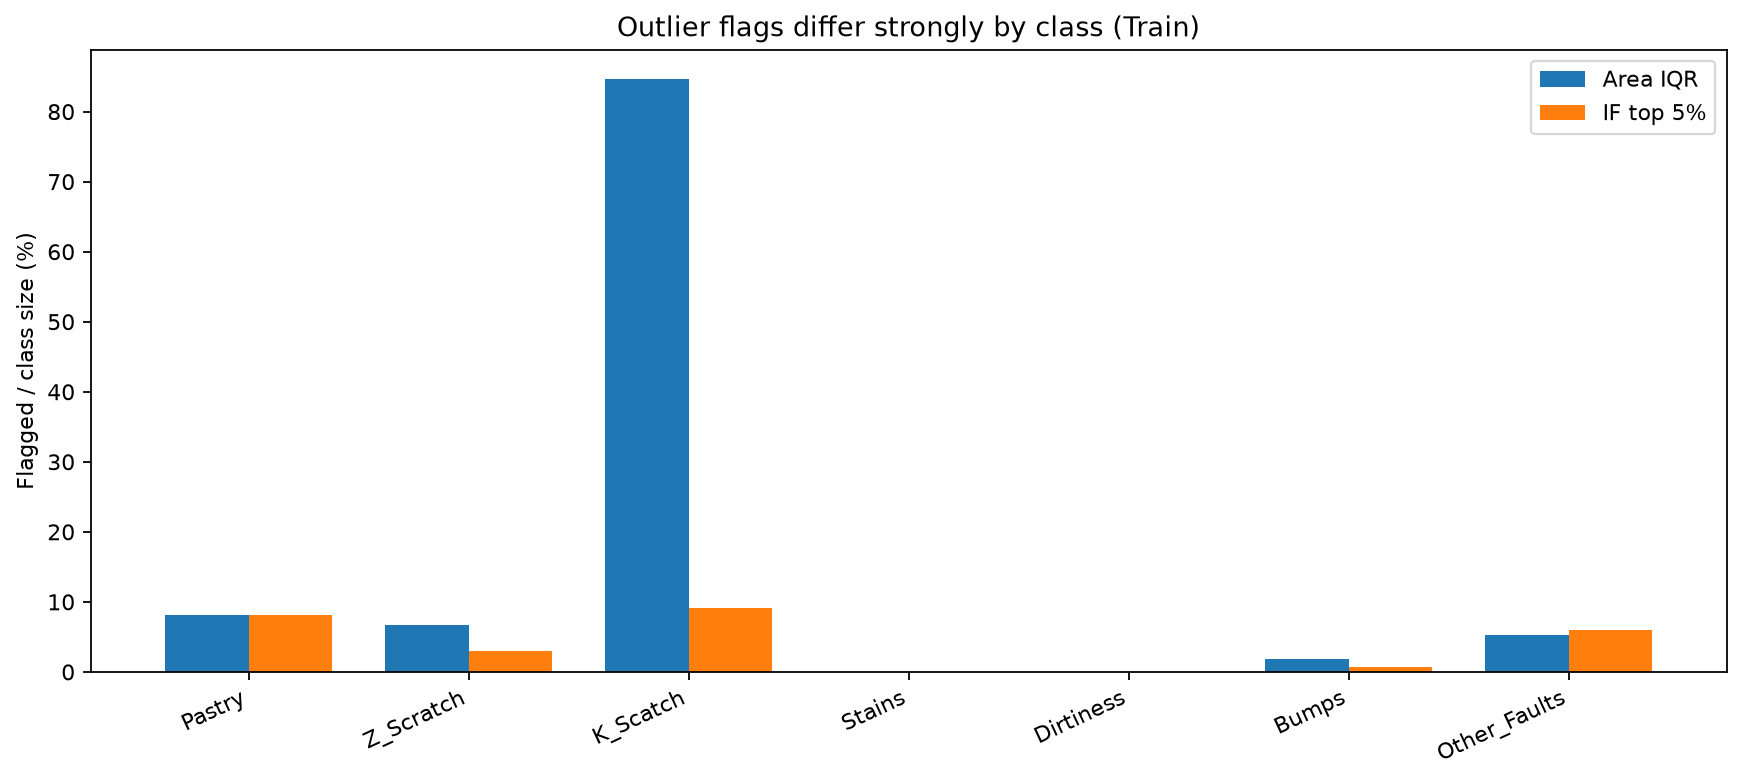

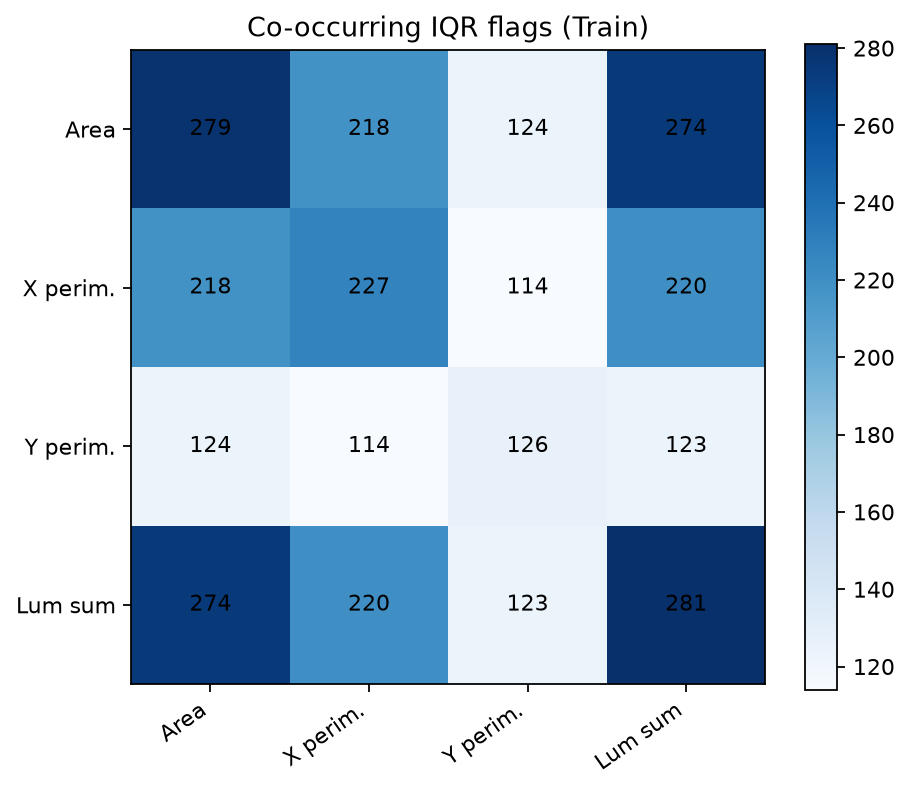

In [12]:
damage_sim = pd.read_csv(OUTLIER_DIR / '07_simulated_deletion_class_damage_NO_DELETE.csv')
print('가상 면적 IQR 후보 삭제에 따른 Train 클래스 손실 (실제 삭제 0건):')
display(damage_sim.loc[damage_sim.simulation_only.eq('remove_area_IQR'),
    ['Fault','before','would_remove','after_if_deleted','class_loss_pct','ACTUAL_REMOVED']].round(2))
print('우선 검토 대상 수 / 구분:')
display(priority_review['review_priority'].value_counts().to_frame('Train 후보 수'))
print('결함 유형별 이상치 비율:')
display(class_outlier_rates[['TrainCount','AreaIQR','AreaIQRRatePct',
                             'Core4AnyIQR','IforestTop5pct','IforestTop5pctRatePct']].round(2))
from IPython.display import Image as NotebookImage
for picture in ['12_class_outlier_rates.png','13_iqr_flag_overlap_heatmap.png']:
    display(NotebookImage(filename=str(OUTLIER_DIR/picture)))

## 5. 결측값 검사·대체: Train으로만 학습

**원본 실측:** 27개 입력의 결측은 0칸(전체 1,941건). 현재 자료에는 실제 보간이 필요한 값이 없다. 그러나 향후 새로운 파일에서도 같은 기준을 쓸 수 있도록 `SimpleImputer`를 파이프라인 내부에 정의한다.

- **연속형 숫자:** Train 중앙값으로 대체(`median`). 평균 대신 중앙값을 선택한 이유는 EDA에서 면적/밝기 합계 등이 오른쪽으로 치우쳤기 때문이다.
- **강종 0/1 이진변수:** Train의 최빈값으로 대체(`most_frequent`)하여 0/1 구조를 보전한다. 원본에는 결측이 없고 두 강종열이 상보적이다. 미래 데이터에서 한쪽만 누락되면 별도 **상보성 재검사**가 필요하다.
- **미래 문자열 열(있는 경우에만):** 최빈값 대체 후 One-Hot Encoding. 현재 원본의 범주형 문자열 입력은 0개다.

`fit`은 Train에서만 하고, Valid/Test 및 추후 실측 신규 데이터에는 저장된 변환기의 `transform`만 적용한다.

In [13]:
missing_by_split = pd.DataFrame({name: chunk[FEATURE_COLS].isna().sum()
                                 for name, chunk in parts.items()})
missing_by_split["All"] = df_clean[FEATURE_COLS].isna().sum()
missing_by_split.to_csv(OUT_DIR / "06_missing_values_by_feature_and_split.csv", encoding="utf-8-sig")
print("전체/Train/Valid/Test 결측값:", missing_by_split.sum().to_dict())
print("결측값이 있는 변수 수:", int(missing_by_split["All"].gt(0).sum()))

NUMERIC_COLS = X_train.select_dtypes(include="number").columns.tolist()
CATEGORICAL_COLS = [c for c in FEATURE_COLS if c not in NUMERIC_COLS]
BINARY_COLS = [c for c in BINARY_STEEL_COLS if c in NUMERIC_COLS]
SCALE_COLS = [c for c in NUMERIC_COLS if c not in BINARY_COLS]
print("연속형 숫자:", len(SCALE_COLS), "개 / 강종 이진:", len(BINARY_COLS),
      "개 / 문자열·범주형:", len(CATEGORICAL_COLS), "개")
assert len(NUMERIC_COLS) + len(CATEGORICAL_COLS) == len(FEATURE_COLS)

전체/Train/Valid/Test 결측값: {'Train': 0, 'Valid': 0, 'Test': 0, 'All': 0}
결측값이 있는 변수 수: 0
연속형 숫자: 25 개 / 강종 이진: 2 개 / 문자열·범주형: 0 개


## 6. 숫자값 표준화: `StandardScaler` (Train 통계 기준)

평균과 표준편차의 단위 차이를 완화하기 위해 연속형 측정 변수에는

\[z = \frac{x - \mu_{\mathrm{Train}}}{\sigma_{\mathrm{Train}}}\]

를 적용한다. **Train의 중앙값 대체 → Train 기준 표준화** 순서이며, Valid/Test에 각각 따로 `fit_transform`을 하지 않는다. 이 과정은 **로지스틱 회귀·SVM·거리 기반 모델**에 특히 중요하고, **랜덤 포레스트·트리 기반 모델**에는 일반적으로 필수적이지 않다. STEP 5에서 트리 전용 미스케일 전처리와 비교할 수 있다.

**강종 변수 2개:** `TypeOfSteel_A300`과 `TypeOfSteel_A400`은 이미 이진(0/1)이므로 표준화하지 않는다. 두 열은 완벽하게 상보적이어서 선형 모델에서 다중공선성을 발생시킬 수 있으나, **첫 Baseline에서는 원본 27개 열을 유지**한다. 이후 규제항(L2) 또는 한 열 제거의 효과를 별도로 비교한다.

## 7. 문자열 원-핫 인코딩 + 학습용 전처리 파이프라인

현재 27개 입력 중 **문자열 변수 0개**이므로 추가 원-핫 변수는 생성하지 않는다. 강종 열은 이미 숫자 0/1이어서 그대로 유지한다. **정답 7개 원-핫 열은 인코딩 대상이 아니라 제외할 타깃**이다.

scikit-learn의 `ColumnTransformer + Pipeline`에 다음 흐름을 묶어서 저장하면 STEP 5에서 동일한 학습 기준을 그대로 재사용할 수 있다.

`X` → (연속형: 중앙값 대체 → 표준화) + (강종 이진: 최빈값 대체) + (문자열: 최빈값 대체 → 원핫) → 숫자형 특성표.

In [14]:
transformers = []
if SCALE_COLS:
    transformers.append(("continuous", Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scaler", StandardScaler()),
    ]), SCALE_COLS))
if BINARY_COLS:
    transformers.append(("steel_binary", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
    ]), BINARY_COLS))
if CATEGORICAL_COLS:
    transformers.append(("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), CATEGORICAL_COLS))

preprocessor = ColumnTransformer(transformers, remainder="drop", sparse_threshold=0,
                                 verbose_feature_names_out=False)
preprocessor.fit(X_train)  # 오직 Train으로만 적합(fit)
learned_columns = list(preprocessor.get_feature_names_out())
output_cols = [c for c in FEATURE_COLS if c in learned_columns]
output_cols += [c for c in learned_columns if c not in output_cols]
assert len(set(output_cols)) == len(output_cols)

def transform_as_frame(x):
    # 반드시 원본 학습 시 사용한 입력 열 순서를 전달
    arr = preprocessor.transform(x[FEATURE_COLS])
    result = pd.DataFrame(np.asarray(arr), index=x.index, columns=learned_columns)
    return result[output_cols]

X_train_final = transform_as_frame(X_train)
X_valid_final = transform_as_frame(X_valid)
X_test_final = transform_as_frame(X_test)

print("Train:", X_train_final.shape, "Valid:", X_valid_final.shape, "Test:", X_test_final.shape)
print("추가 One-Hot 변수 수:", len(output_cols) - len(FEATURE_COLS))
print("출력 변수명(앞부분):", output_cols[:12])
display(X_train_final.head(3))

Train: (1358, 27) Valid: (291, 27) Test: (292, 27)
추가 One-Hot 변수 수: 0
출력 변수명(앞부분): ['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300']


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas
625,-1.000961,-0.795851,0.059176,0.059190,1.217406,0.866754,0.483784,1.064993,-1.503357,-0.322079,-0.697921,0.0,1.0,-0.690554,-0.899274,0.291462,-0.586579,1.513657,0.095955,-1.153390,-1.181731,1.669309,1.838389,0.988019,-1.332684,-0.426223,1.206545
1584,1.400475,1.392179,-0.294247,-0.294267,-0.455948,-0.482998,-0.522594,-0.439375,0.637975,-0.159784,1.608681,1.0,0.0,0.039585,0.427653,-0.373719,0.367419,-0.441555,0.576967,-0.823742,-1.181731,-0.903367,-0.539926,-1.120443,-0.822546,0.315484,-1.144854
434,-1.004810,-0.799877,-0.265056,-0.264998,2.909956,3.440212,2.961675,2.964459,-1.720593,0.597588,-0.405240,0.0,1.0,-0.690554,-0.914979,0.498829,1.112975,1.451999,-1.587381,-1.940293,-1.181731,2.049553,1.838389,1.710259,-0.423670,0.230717,1.206545


### 7-1. 스케일링 결과가 의도한 대로 적용되었는가?

**Train**의 표준화 대상은 평균 약 0, 표준편차 약 1이어야 한다(상수열은 예외). **Valid/Test는 반드시 0과 1이 될 필요가 없다.** 이것이 오히려 Train 기준 변환이 적용됐다는 증거다. 강종 이진 변수는 0/1로 유지되어야 한다.

In [15]:
scale_summary = pd.DataFrame({
    "train_mean_after": X_train_final[SCALE_COLS].mean(),
    "train_std_after_ddof0": X_train_final[SCALE_COLS].std(ddof=0),
    "valid_mean_after": X_valid_final[SCALE_COLS].mean(),
    "test_mean_after": X_test_final[SCALE_COLS].mean(),
})
scale_summary.to_csv(OUT_DIR / "07_standardization_audit.csv", encoding="utf-8-sig")
print("Train 평균 절댓값 최댓값:", float(scale_summary["train_mean_after"].abs().max()))
print("Train 표준편차 범위:", (float(scale_summary["train_std_after_ddof0"].min()),
                                float(scale_summary["train_std_after_ddof0"].max())))
display(scale_summary.head(8).round(5))

if SCALE_COLS:
    not_constant = X_train[SCALE_COLS].nunique(dropna=True) > 1
    assert np.allclose(scale_summary["train_mean_after"], 0, atol=1e-10)
    assert np.allclose(scale_summary.loc[not_constant, "train_std_after_ddof0"], 1, atol=1e-10)
for name, chunk in [("Train", X_train_final), ("Valid", X_valid_final), ("Test", X_test_final)]:
    for col in BINARY_COLS:
        assert chunk[col].isin([0, 1]).all(), f"{name}/{col}의 이진 형식 확인 필요"
print("[통과] Train의 표준화 통계 및 강종 0/1 유지")

Train 평균 절댓값 최댓값: 7.90073292340023e-16
Train 표준편차 범위: (0.9999999999999998, 1.0000000000000002)


,train_mean_after,train_std_after_ddof0,valid_mean_after,test_mean_after
X_Minimum,0.0,1.0,0.03564,0.09172
X_Maximum,0.0,1.0,0.02723,0.08780
Y_Minimum,0.0,1.0,-0.01027,-0.05273
Y_Maximum,0.0,1.0,-0.01028,-0.05269
Pixels_Areas,0.0,1.0,-0.00373,0.05027
X_Perimeter,0.0,1.0,0.00368,0.13213
Y_Perimeter,0.0,1.0,-0.00602,0.46536
Sum_of_Luminosity,-0.0,1.0,0.00275,0.00467


[통과] Train의 표준화 통계 및 강종 0/1 유지


### 7-2. 스케일링 전·후 비교 시각화 (Train 전용)

STEP 3에서 확인한 **면적과 명암의 큰 값 범위**가 표준화 이후 서로 비교 가능한 축으로 변환됐는지 확인한다. 히스토그램에서는 **분포의 비대칭(왜도)이 사라지는 것이 아니다.** 표준화는 중심·규모를 조정할 뿐 극단값을 자동 제거하거나 정규분포로 바꾸지 않는다.

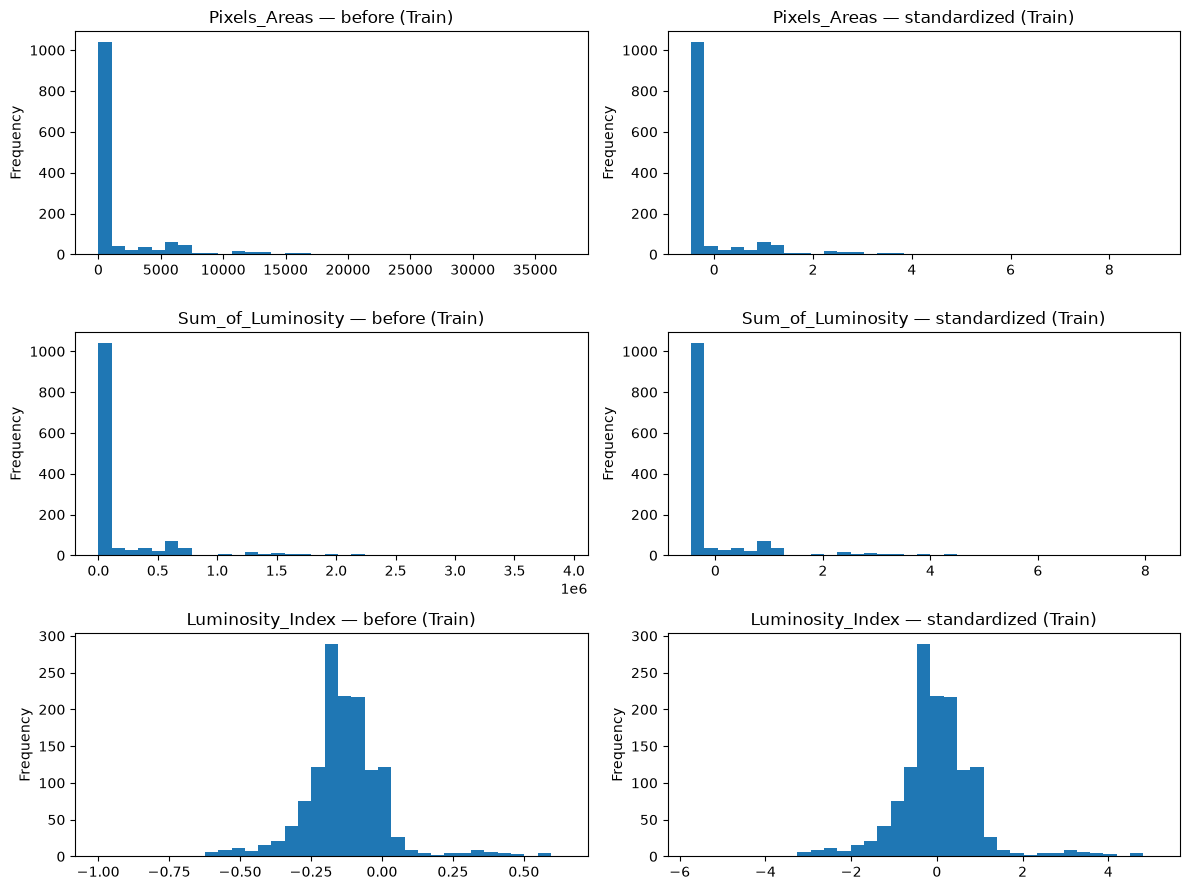

In [16]:
view_features = ["Pixels_Areas", "Sum_of_Luminosity", "Luminosity_Index"]
fig, axes = plt.subplots(len(view_features), 2, figsize=(12, 9))
for row, feat in enumerate(view_features):
    axes[row, 0].hist(X_train[feat], bins=35)
    axes[row, 0].set_title(feat + " — before (Train)")
    axes[row, 1].hist(X_train_final[feat], bins=35)
    axes[row, 1].set_title(feat + " — standardized (Train)")
    for ax in axes[row]: ax.set_ylabel("Frequency")
fig.tight_layout()
fig.savefig(OUT_DIR / "08_train_before_after_scaling.png", dpi=160, bbox_inches="tight")
plt.show()

## 7-B. 이상치 대응용 실제 전처리 대안 2종 생성

기존 `StandardScaler` 전처리는 **STEP 5 비교의 기준선으로 유지**하고, 이번 이상치 심층 분석에서는 다음 두 개의 실험용 변환을 추가로 실행합니다. **어느 변환도 행을 제거하거나 극단값을 임의의 상한으로 바꾸지 않습니다.** 모든 변환기는 **Train에서만 `.fit()`** 후 Valid/Test에는 `.transform()`만 적용합니다.

- **대안 A – RobustScaler**: 연속형 특성 25개를 Train 중앙값·IQR로 변환하여, 학습 기준이 일부 극단값에 과도하게 좌우되는 문제를 줄입니다. 값이 0~1로 제한되는 것은 아닙니다.
- **대안 B – log1p + StandardScaler**: Train에서 왜도가 큰 원시 면적·X둘레·Y둘레·밝기 합계 4개에만 `log(1+x)`를 적용하여 꼬리 비대칭을 완화한 후 표준화합니다. 이미 로그 파생된 `LogOfAreas` 등은 재로그하지 않습니다.
- 두 대안 모두 강종 이진 2열을 그대로 유지하고, 원본 변수명 27개 + 결함 정답 1개로 결과 CSV를 저장합니다.

**변환 방식에 따른 모델 정확도 향상은 아직 검증되지 않았습니다.** STEP 5에서 동일 Train/Valid 분할의 Macro F1·클래스별 Recall로 비교해야 합니다.

In [17]:
outlier_variants_audit = fit_lossless_variants(
    X_train, X_valid, X_test, y_train, y_valid, y_test,
    FEATURE_COLS, OUTLIER_DIR
)
display(outlier_variants_audit)
log_sensitivity = pd.read_csv(OUTLIER_DIR / '08_log1p_train_skew_sensitivity.csv')
print('로그 변환 전후 Train 왜도 비교 (특성별 왜도 단순 진단, 모델 성능 비교 아님):')
display(log_sensitivity[['feature','raw_skew','log1p_skew','actual_rows_removed']].round(3))
assert outlier_variants_audit['actual_removed'].eq(0).all()
assert outlier_variants_audit['n_rows'].sum() == 1941*2
assert outlier_variants_audit['missing_cells'].sum() == 0
print('[검증 통과] 두 변환 대안 모두 1,941건 보존 / 27개 입력·1개 정답 / 결측값 0')

,strategy,split,n_rows,n_features,missing_cells,actual_removed,fitted_on
0,robust,train,1358,27,0,0,Train only
1,robust,valid,291,27,0,0,Train only
2,robust,test,292,27,0,0,Train only
3,log1p_standard,train,1358,27,0,0,Train only
4,log1p_standard,valid,291,27,0,0,Train only
5,log1p_standard,test,292,27,0,0,Train only


로그 변환 전후 Train 왜도 비교 (특성별 왜도 단순 진단, 모델 성능 비교 아님):


,feature,raw_skew,log1p_skew,actual_rows_removed
0,Pixels_Areas,3.160,0.732,0
1,X_Perimeter,2.869,0.833,0
2,Y_Perimeter,2.834,0.647,0
3,Sum_of_Luminosity,3.290,0.754,0


[검증 통과] 두 변환 대안 모두 1,941건 보존 / 27개 입력·1개 정답 / 결측값 0


## 8. 불균형 대응은 별도 처리: Train 클래스 가중치 준비

EDA 전체 기준 `Other_Faults` 673건, `Dirtiness` 55건으로 최대/최소 비율이 약 12.24배이다. **전처리 자체에서 무작정 소수 클래스를 복제하거나 SMOTE를 실행하지 않는다.** 합성 관측치를 분할 **이전에** 만들면 검증 데이터가 오염될 수 있기 때문이다.

대신 Train의 빈도만으로 `class_weight='balanced'`에 해당하는 참조 가중치 `n_samples / (n_classes × n_class_samples)`를 산출·저장한다. STEP 5에서 **가중치 미적용 Baseline**과 가중치 적용 모델을 Valid의 **Macro F1 / 클래스별 Recall / 혼동행렬**로 비교한다. RandomForestClassifier와 LogisticRegression은 `class_weight='balanced'` 옵션을 직접 지원한다.

In [18]:
classes = np.array(FAULT_COLS)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weight_map = {name: float(weight) for name, weight in zip(classes, weights)}
weight_table = pd.DataFrame({"Class": classes,
                             "TrainCount": y_train.value_counts().reindex(classes).to_numpy(),
                             "BalancedWeight": weights})
weight_table.to_csv(OUT_DIR / "09_train_class_weights.csv", index=False, encoding="utf-8-sig")
print("학습 데이터 기준 클래스 가중치(권장 비교 옵션, 기본 모델에 자동 적용되지 않음):")
display(weight_table.round(4))

학습 데이터 기준 클래스 가중치(권장 비교 옵션, 기본 모델에 자동 적용되지 않음):


,Class,TrainCount,BalancedWeight
0,Pastry,110,1.7636
1,Z_Scratch,133,1.4586
2,K_Scatch,273,0.7106
3,Stains,50,3.8800
4,Dirtiness,39,4.9744
5,Bumps,282,0.6879
6,Other_Faults,471,0.4119


## 9. 최종 품질검증: 데이터 누수·중복·결측·형식·표본 손실 없음

저장하기 전에 다음을 모두 확인한다.

1. Train/Valid/Test가 서로 다른 **원본 행**을 사용하며, 서로 같은 27개 입력을 공유하지 않는다.
2. 각 분할의 **X에 7개 정답 원-핫 열 또는 `Fault`가 없어야** 한다.
3. 세 분할의 **입력 특성명·순서가 동일**, 모든 값이 **유한한 숫자**여야 한다.
4. **관측치 수 보존**, **정답의 원본 순서와 X의 정렬 유지**, **이진 강종 유지**.
5. 저장 직전 **입력 파일 SHA-256 불변**을 확인한다.

`pandas`의 인덱스 검사는 원본 행의 재사용 여부를, `hash_pandas_object` 검사는 서로 다른 행에 동일한 측정값이 남아 있는지 점검한다. 완전 중복이 0개인 현재 데이터에서 서로 겹치는 입력이 없음을 기대한다.

In [19]:
assert X_train_final.columns.equals(X_valid_final.columns)
assert X_train_final.columns.equals(X_test_final.columns)
assert len(X_train_final) + len(X_valid_final) + len(X_test_final) == len(df_clean)
assert len(y_train) == len(X_train_final) and len(y_valid) == len(X_valid_final) and len(y_test) == len(X_test_final)
assert all(not any(label in X.columns for label in FAULT_COLS + ["Fault"])
           for X in (X_train_final, X_valid_final, X_test_final))
for name, X in [("Train", X_train_final), ("Valid", X_valid_final), ("Test", X_test_final)]:
    assert not X.isna().to_numpy().any(), f"{name}에 결측치 존재"
    assert np.isfinite(X.to_numpy(dtype=float)).all(), f"{name}에 무한대 또는 비수치형 존재"
assert not (set(X_train_final.index) & set(X_valid_final.index) or
            set(X_train_final.index) & set(X_test_final.index) or
            set(X_valid_final.index) & set(X_test_final.index))

# 입력 27개 특성 기준의 동일 관측치가 분할 간 겹치는지 체크(정답과 무관하게 검사)
def feature_hash_set(X):
    return set(pd.util.hash_pandas_object(X[FEATURE_COLS], index=False).to_numpy().tolist())
split_hashes = {name: feature_hash_set(chunk[FEATURE_COLS]) for name, chunk in parts.items()}
overlap_check = {
    "Train-Valid": len(split_hashes["Train"] & split_hashes["Valid"]),
    "Train-Test": len(split_hashes["Train"] & split_hashes["Test"]),
    "Valid-Test": len(split_hashes["Valid"] & split_hashes["Test"]),
}
assert all(v == 0 for v in overlap_check.values()), overlap_check
assert file_sha256(source_path) == SOURCE_HASH_BEFORE, "원본 파일이 변경되었습니다"
print("모든 무결성 검사 통과!")
print("분할 간 동일 원본 입력의 해시 중복 수:", overlap_check)
print("원본 파일 해시 유지:", SOURCE_HASH_BEFORE[:16] + "...")

모든 무결성 검사 통과!
분할 간 동일 원본 입력의 해시 중복 수: {'Train-Valid': 0, 'Train-Test': 0, 'Valid-Test': 0}
원본 파일 해시 유지: d85b45f6c0911992...


## 10. 전처리 결과·변환기·진단표 저장

`outputs_preprocessing/`에 저장되는 핵심 파일:

| 이름 | 주요 내용 | 후속 활용 |
|---|---|---|
| `train_preprocessed.csv` | Train의 표준화된 27개 입력 + `Fault` 정답 | STEP 5 모델 학습 |
| `valid_preprocessed.csv` | Train 기준으로 변환한 Valid | STEP 5 모델 선택 |
| `test_preprocessed.csv` | Train 기준으로 변환한 Test | **모델 확정 후** 최종 평가에만 사용 |
| `preprocessor.joblib` | **Train에서 fit된 ColumnTransformer** | 신규 데이터/Valid/Test 동일 기준 변환 |
| `preprocessing_manifest.json` | seed·분할·변수·입력 해시·실행 환경 기록 | 재현성 |
| `STEP4_전처리_실측_보고서.md` | 실제 계산 수치·의사결정·주의점 | 보고서·발표 원고 기반 |
| 기타 `.csv/.png` | 클래스·결측·IQR·상관·스케일링 점검표, 시각화 | 팀 회의·검증 |

저장된 CSV에는 정답 `Fault`를 **별도 열로만** 추가한다. 모델 학습 시 반드시 `X = data.drop(columns='Fault')`, `y = data['Fault']`로 다시 분리한다. `.joblib` 파일은 **신뢰할 수 있는 프로젝트 내부 산출물만 로드**해야 한다.

In [20]:
for name, X, y in [("train", X_train_final, y_train),
                   ("valid", X_valid_final, y_valid),
                   ("test", X_test_final, y_test)]:
    assert X.index.equals(y.index)
    output_df = X.copy()
    output_df["Fault"] = y
    output_df.to_csv(OUT_DIR / f"{name}_preprocessed.csv", index=False, encoding="utf-8-sig")
    print(f"저장: {name}_preprocessed.csv {output_df.shape}")

joblib.dump(preprocessor, OUT_DIR / "preprocessor.joblib")
quality_table.to_csv(OUT_DIR / "00_raw_quality_checks.csv", index=False, encoding="utf-8-sig")
split_counts.to_csv(OUT_DIR / "01_class_counts_by_split.csv", encoding="utf-8-sig")
split_pct.to_csv(OUT_DIR / "01_class_percent_by_split.csv", encoding="utf-8-sig")

split_ids = pd.concat([
    pd.DataFrame({"original_index": chunk.index, "split": name, "Fault": chunk["Fault"].to_numpy()})
    for name, chunk in parts.items()
], ignore_index=True).sort_values("original_index")
split_ids.to_csv(OUT_DIR / "10_split_assignment_audit.csv", index=False, encoding="utf-8-sig")

manifest = {
    "source": source_path.name, "source_sha256": SOURCE_HASH_BEFORE,
    "rows_original": len(df_raw), "rows_after_full_duplicate_removal": len(df_clean),
    "full_duplicate_removed": full_dup_count, "conflicting_label_groups": conflict_groups,
    "core8_matching_pairs": audit_summary["core8_matching_pairs"],
    "semantic_near_candidate_pairs": audit_summary["near_candidate_pairs"],
    "semantic_near_candidate_cross_split_pairs": audit_summary["near_candidate_cross_split_pairs"],
    "bbox_overlap_iou_ge_0_5_pairs": audit_summary["bbox_iou_ge_0_5_pairs"],
    "semantic_duplicate_proven": False, "semantic_duplicate_resolution": "pending source image/coil ID",
    "features_original": FEATURE_COLS, "fault_labels": FAULT_COLS,
    "continuous_features_scaled": SCALE_COLS, "binary_steel_features_preserved": BINARY_COLS,
    "categorical_string_features": CATEGORICAL_COLS,
    "output_features": output_cols,
    "random_state": SEED, "requested_ratios": {"train": TRAIN_RATIO, "valid": VALID_RATIO, "test": TEST_RATIO},
    "split_sizes": {name.lower(): len(chunk) for name, chunk in parts.items()},
    "missing_values_original": int(df_raw[FEATURE_COLS].isna().sum().sum()),
    "iqr_area_candidates_train": int(area_flags.sum()),
    "high_corr_pairs_abs_r_ge_0_8_train": int(len(strong_corr)),
    "outlier_removed_count": 0, "imbalance_strategy": "stratify split only; weights for future comparison; no SMOTE",
    "dataset_temporal_or_coil_group_id_available": False,
    "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                 "numpy": np.__version__, "scikit_learn": sklearn.__version__},
}
(OUT_DIR / "preprocessing_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
(OUT_DIR / "train_class_weights.json").write_text(json.dumps(class_weight_map, ensure_ascii=False, indent=2), encoding="utf-8")
print("저장 객체: preprocessor.joblib, preprocessing_manifest.json, train_class_weights.json")

저장: train_preprocessed.csv (1358, 28)
저장: valid_preprocessed.csv (291, 28)
저장: test_preprocessed.csv (292, 28)
저장 객체: preprocessor.joblib, preprocessing_manifest.json, train_class_weights.json


### 10-1. 전처리 실측 보고서 자동 작성

노트북을 다시 실행하면 **실제 입력 데이터와 Train에서 산출한 결과**를 토대로 Markdown 보고서를 갱신한다. 아래 보고서는 별도의 조사 자료가 아니라 본 파일 실행 결과를 요약한 것이다.

In [21]:
report = [
    "# STEP 4 – Steel Plates Faults 데이터 전처리 실측 보고서", "",
    "## 1. 입력 데이터와 구조", "",
    f"- 데이터 출처: `{source_path.name}` (SHA-256: `{SOURCE_HASH_BEFORE}`)",
    f"- 원본 데이터: **{len(df_raw):,}행 × {df_raw.shape[1]}열**, 입력 {len(FEATURE_COLS)}개 / 정답 {len(FAULT_COLS)}개",
    f"- 결측: **{na_total}칸**, 완전 중복: **{full_dup_count}건**, 정답 충돌: **{conflict_groups}그룹**",
    f"- 원-핫 정답 형식 검증: **{'통과' if label_ok else '실패'}**", "",
    "## 2. 원본 7개 클래스의 구성", "",
    "| 클래스 | 원본 건수 | 구성비(%) |", "|---|---:|---:|",
]
for lbl in FAULT_COLS:
    report.append(f"| {lbl} | {int(class_overview.loc[lbl, 'Count'])} | {class_overview.loc[lbl, 'Percent']:.2f} |")
report.extend([
    "", "## 3. Train/Valid/Test (층화, random_state=42)", "",
    "| 클래스 | Train | Valid | Test |", "|---|---:|---:|---:|",
])
for lbl in FAULT_COLS:
    r = split_counts.loc[lbl]
    report.append(f"| {lbl} | {r['Train']} | {r['Valid']} | {r['Test']} |")
report.extend([
    f"| **합계** | **{len(train_df)}** | **{len(valid_df)}** | **{len(test_df)}** |",
    "", "## 4. EDA 기반 전처리 선택", "",
    f"- Train `Pixels_Areas` 평균 **{X_train['Pixels_Areas'].mean():,.2f}**, 중앙값 **{X_train['Pixels_Areas'].median():,.1f}**, 왜도 **{X_train['Pixels_Areas'].skew():.2f}**.",
    f"- IQR 이상값 후보: `Pixels_Areas` **{int(area_flags.sum())}건**, `Sum_of_Luminosity` **{int(outlier_table.set_index('Feature').loc['Sum_of_Luminosity', 'OutlierCandidates'])}건**. **0건 삭제**.",
    f"- 절댓값 피어슨 상관계수 ≥ 0.80인 Train 변수쌍: **{len(strong_corr)}개**. 자동 삭제하지 않음.",
    f"- 처리: Train 중앙값 결측 대체 + **연속형 {len(SCALE_COLS)}개 표준화**, **강종 이진 {len(BINARY_COLS)}개 원형 유지**.",
    f"- 추가 문자열 입력 {len(CATEGORICAL_COLS)}개 → 신규 One-Hot 인코딩 열 {len(output_cols)-len(FEATURE_COLS)}개.",
    "- 이유: 이상값은 물리적 관측을 반영할 수 있으며, 로그 면적(`LogOfAreas`)도 원본 변수에 이미 포함됨.",
    "", "## 5. 품질 검증·누수 통제", "",
    "- 중복 검사 후 분할, Train-only fit / Valid·Test-only transform을 준수함.",
    f"- 분할 간 동일 입력: {overlap_check}. 원본 파일 SHA-256 변경 없음.",
    "- 정답 7개 원-핫 열과 `Fault`는 모델의 입력 X에서 제외함.",
    "- **주의:** 원본에 생산 일시·코일/배치 식별자가 없으므로 시간/그룹 외삽 성능은 별도 검증해야 함.",
    "", "## 6. STEP 5 제안", "",
    "- Baseline에서 동일 27개 입력으로 Dummy / Logistic Regression / Random Forest 등을 비교.",
    "- Accuracy와 함께 **Macro F1**, 7개 클래스별 Recall/F1 및 혼동행렬을 보고.",
    "- Train에서만 계산한 클래스 가중치는 Baseline 이후 별도 비교 실험에 사용. Test는 최종 평가 전까지 미사용.",
    "- 로지스틱 회귀의 중복 변수/규제항 및 면적 로그 변환은 추후 실험에서 검증.",
    "", "## 7. 재현성", "",
    "- `preprocessing_manifest.json`과 `preprocessor.joblib`에 설정·변환기를 저장함.",
    "- 결과값은 첨부된 실제 데이터의 실행 결과이며, 산업 현장 일반화 성능을 의미하지 않음.",
])
report.extend([
    "", "## 8. 의미론적 중복 후보 추가 검증", "",
    f"- 27개 입력 전체를 비교한 정확 중복: **{audit_summary['input_exact_duplicates']}건**.",
    f"- 주요 측정값 8개 정확 일치 후보: **{audit_summary['core8_matching_pairs']}쌍**.",
    f"- 면적·둘레 ±2%, 밝기 최솟값/최댓값 차이 ±5인 유사 후보: **{audit_summary['near_candidate_pairs']}쌍** (서로 다른 분할 간 **{audit_summary['near_candidate_cross_split_pairs']}쌍**).",
    f"- 경계상자 IoU >= 0.5인 후보: **{audit_summary['bbox_iou_ge_0_5_pairs']}쌍**.",
    "- 대표 후보: 1,776행(Test)과 1,777행(Valid)은 27개 입력 중 23개가 같고 경계상자 IoU가 0.52.",
    "- 현재 자료에 결함 이미지·코일 ID·생산 배치 ID가 없어 **의미론적 중복 여부를 확정할 수 없음**.",
    "- 의미론적 중복 후보는 추가 확인이 필요하므로 자동 삭제 0건. 가능하면 원본 식별자를 확보해 그룹 단위 재분할할 것.",
    "- 별도 분석 파일: `11_core_measurement_matching_pairs.csv`, `12_near_duplicate_candidate_pairs.csv`, `13_overlapping_bounding_boxes.csv`, `STEP4_의미론적중복_추가검증_보고서.md`.",
])
report_path = OUT_DIR / "STEP4_전처리_실측_보고서.md"
report_path.write_text("\n".join(report) + "\n", encoding="utf-8")
print("보고서 저장:", report_path.name)
print("\n".join(report[:18]))

보고서 저장: STEP4_전처리_실측_보고서.md
# STEP 4 – Steel Plates Faults 데이터 전처리 실측 보고서

## 1. 입력 데이터와 구조

- 데이터 출처: `steel_plates_faults.csv` (SHA-256: `d85b45f6c09119926bf5abb7192d7bfd113e8e3821778a3e7b6f0ff0a5bb2122`)
- 원본 데이터: **1,941행 × 34열**, 입력 27개 / 정답 7개
- 결측: **0칸**, 완전 중복: **0건**, 정답 충돌: **0그룹**
- 원-핫 정답 형식 검증: **통과**

## 2. 원본 7개 클래스의 구성

| 클래스 | 원본 건수 | 구성비(%) |
|---|---:|---:|
| Pastry | 158 | 8.14 |
| Z_Scratch | 190 | 9.79 |
| K_Scatch | 391 | 20.14 |
| Stains | 72 | 3.71 |
| Dirtiness | 55 | 2.83 |


## 11. 저장 후 재현성 검증 및 STEP 5 연결

1. 저장한 `preprocessor.joblib`를 **다시 읽어** Train과 Valid를 변환한 결과가 완전히 같은지 확인한다.
2. 저장된 Train/Valid/Test CSV의 결측값·행 수·정답을 확인한다.
3. STEP 5에서는 **이미 전처리된 CSV를 모델 입력으로 쓸 때 동일 스케일러를 다시 적용하지 않는다.** 반대로 원본 입력에서 모델링한다면 저장된 변환기를 사용한다. 이 둘을 혼용하지 않는다.

> **안전 주의:** `joblib.load()`는 피클 계열 역직렬화를 사용하므로, 이 노트북이 직접 생성한 신뢰할 수 있는 파일에만 사용한다.

In [22]:
loaded_preprocessor = joblib.load(OUT_DIR / "preprocessor.joblib")
for name, X, result in [("Train", X_train, X_train_final),
                         ("Valid", X_valid, X_valid_final),
                         ("Test", X_test, X_test_final)]:
    again = pd.DataFrame(np.asarray(loaded_preprocessor.transform(X[FEATURE_COLS])),
                         index=X.index, columns=learned_columns)[output_cols]
    np.testing.assert_allclose(again.to_numpy(dtype=float), result.to_numpy(dtype=float), atol=1e-12, rtol=0)
    print("[통과] 저장 파이프라인으로", name, "변환 재현")
for label, expected in [("train", len(train_df)), ("valid", len(valid_df)), ("test", len(test_df))]:
    saved = pd.read_csv(OUT_DIR / f"{label}_preprocessed.csv")
    assert saved.shape == (expected, len(output_cols) + 1)
    assert saved["Fault"].isin(FAULT_COLS).all()
    assert not saved.isna().any().any()
print("[통과] 저장 CSV의 데이터 수, 결측, 타깃 형식 검증")
print("\n산출물 파일:")
for f in sorted(OUT_DIR.iterdir()):
    print(" -", f.name)

[통과] 저장 파이프라인으로 Train 변환 재현
[통과] 저장 파이프라인으로 Valid 변환 재현
[통과] 저장 파이프라인으로 Test 변환 재현
[통과] 저장 CSV의 데이터 수, 결측, 타깃 형식 검증

산출물 파일:
 - 00_raw_quality_checks.csv
 - 01_class_counts_by_split.csv
 - 01_class_distribution_and_split.png
 - 01_class_percent_by_split.csv
 - 02_train_descriptive_statistics.csv
 - 03_train_iqr_outlier_candidates.csv
 - 04_train_high_correlation_pairs.csv
 - 05_area_iqr_candidates_by_class.csv
 - 06_missing_values_by_feature_and_split.csv
 - 07_standardization_audit.csv
 - 08_train_before_after_scaling.png
 - 09_train_class_weights.csv
 - 10_split_assignment_audit.csv
 - 11_core_measurement_matching_pairs.csv
 - 12_near_duplicate_candidate_pairs.csv
 - 13_overlapping_bounding_boxes.csv
 - 14_semantic_duplicate_audit_summary.csv
 - 15_near_duplicate_pairs_by_split.csv
 - 16_derived_feature_redundancy_checks.csv
 - outliers_advanced
 - preprocessing_manifest.json
 - preprocessing_objects.joblib
 - preprocessor.joblib
 - STEP4_의미론적중복_추가검증_보고서.md
 - STEP4_전처리_실측_보고서.md
 - 

## 12. 심층 이상치 검증 최종 보고서·이력 기록

아래 셀에서는 지금까지 계산한 실제 결과로 **이상치 전용 상세 보고서**, 검사 기준·검토 행 목록·클래스 편향 시뮬레이션·그림 파일을 출력하고, 기존 `preprocessing_manifest.json`과 STEP 4 보고서에 새로운 감사 결과를 추가합니다.

**핵심 최종 결정:** 1,941건 유지. IQR/MAD/IsolationForest 검출은 **검토용 플래그**만 부여. 밝기 간 불일치가 의심되는 519·592행의 원자료 확인 필요. Baseline 표준화와 RobustScaler/log1p 두 가지 lossless 대안을 별도 저장하며, Test 결과를 이용한 방법 선택은 하지 않습니다.

In [23]:
outlier_report_path = make_report(
    outlier_results, train_outlier_rules, class_outlier_rates, luminosity_review, OUTLIER_DIR
)
manifest_path = OUT_DIR / 'preprocessing_manifest.json'
manifest_final = json.loads(manifest_path.read_text(encoding='utf-8'))
manifest_final['advanced_outliers'] = {
    **outlier_results,
    'extra_output_dir': 'outputs_preprocessing/outliers_advanced',
    'strategies': ['baseline_standard', 'robust_trainfit', 'log1p_standard_trainfit'],
    'source_error_review_required': True,
    'source_changes': 0,
}
manifest_path.write_text(json.dumps(manifest_final, ensure_ascii=False, indent=2), encoding='utf-8')
with (OUT_DIR / 'STEP4_전처리_실측_보고서.md').open('a', encoding='utf-8') as file:
    file.write('\n\n## 9. 심층 이상치 전처리 추가 결과\n\n')
    file.write(f"- Train IQR: 면적 {outlier_results['iqr_area_train']}건, 밝기 합계 {outlier_results['iqr_sum_lum_train']}건, X 둘레 {outlier_results['iqr_xperimeter_train']}건.\n")
    file.write(f"- Train 4개 핵심 변수 중 하나라도 이상치: {outlier_results['any_core4_iqr_train']}건; 둘 이상: {outlier_results['core4_atleast2_iqr_train']}건.\n")
    file.write(f"- IF 상위 5% 검토 후보: {outlier_results['iforest_top5pct_train']}건; 사전 정의 기준에 따른 검토 대상이지 오류 확정 아님.\n")
    file.write('- 산술적 일관성 점검: 원본 519행/592행은 픽셀별 밝기 통계가 동일한 영역을 가리킨다는 전제에서 밝기 평균이 최소 밝기보다 낮음. 원본 확인 필요.\n')
    file.write('- **K_Scatch의 면적 IQR 삭제 모의 실험: 273건 중 231건(84.62%)을 잃게 됨. 실제 0건 제거.**\n')
    file.write('- Train-only RobustScaler 및 log1p+StandardScaler 대안 2종, 각 Train/Valid/Test CSV 별도 저장.\n')
    file.write('- 상세 경로: `outliers_advanced/STEP4_이상치_고도화_실측_보고서.md`.\n')
assert file_sha256(source_path) == SOURCE_HASH_BEFORE
assert sum([len(train_df), len(valid_df), len(test_df)]) == 1941
print('심층 검증 보고서:', outlier_report_path.resolve())
print('원본 파일 변경 없음 / 삭제 0건 / 모든 변환기 Train-only fit: 최종 검증 통과')

심층 검증 보고서: C:\Users\sgr10\Desktop\steel_fault_project\outputs_preprocessing\outliers_advanced\STEP4_이상치_고도화_실측_보고서.md
원본 파일 변경 없음 / 삭제 0건 / 모든 변환기 Train-only fit: 최종 검증 통과


## STEP 5 연결을 위한 최종 선택 지침

**모델 성능을 측정하기 전의 전처리 권장 순서:** (1) 동일 Train·Validation 분할을 고정하고 기본 표준화 파일로 Baseline 모델 학습 → (2) 강건 변환/로그 변환 대안으로 **동일 모델**을 다시 학습 → (3) Validation Macro F1, 7개 클래스별 Recall, 혼동행렬을 비교 → (4) 선택된 전처리·모델로 최종 Test를 **한 번만 평가**합니다.

표본의 크기·밝기·형상 차이는 결함 분류의 정보일 수 있으므로 무조건 클리핑/삭제하지 않습니다. 단, 원본 자료로 산술 불일치를 확인하여 명백한 오류라고 입증된 행만 별도 수정본의 필요성을 판단하고, 수정 시엔 Train/Valid/Test 분할부터 전처리를 재실행해야 합니다.

## 최종 결론 및 팀 발표에 활용할 해석

**검증된 사실:** 1,941개 원본 강판 측정치에는 결측값과 완전 중복 데이터가 없으며, 7개 결함 유형은 균형적이지 않다. Train/Valid/Test를 1,358/291/292건으로 층화 분리했고, EDA에서 큰 면적·명암값이 있다는 사실만으로 관측치를 삭제하지 않았다. 27개 입력 특성 중 연속형 25개에는 Train 기준 중앙값 대체·표준화를, 강종 이진 2개에는 0/1 보존 처리를 적용했다. 원본의 문자열 입력이 없으므로 추가 One-Hot 인코딩 열은 생기지 않는다.

**선택의 이유:** 원본 IQR 후보는 실제 결함의 특징일 수 있으며, 소수 유형을 과도하게 삭제하면 검증의 대표성이 떨어질 수 있다. 변수 간 높은 선형 상관관계도 그 자체로 제거 근거가 되지 않는다. 초기 Baseline을 위한 **동일한 27개 입력을 유지한 표준 전처리**가 결과 비교를 명확하게 한다.

**STEP 5에 넘길 파일:** `outputs_preprocessing/train_preprocessed.csv`, `valid_preprocessed.csv`, `test_preprocessed.csv`. `Fault`는 정답이므로 모델 입력에서 빼야 하며, Valid는 모델 선택, Test는 모델 확정 후 최종 평가에만 사용한다.

**한계:** 랜덤 층화 분할은 같은 생산 코일/배치나 미래 시점에 대한 독립성을 보장하지 않는다. 실제 공정 적용 전에는 그룹·시간 기준 분리 및 신규 생산 데이터 재검증이 추가로 필요하다.

**추가 검증 결과(중요):** 완전 중복 0건은 의미론적 중복 0건을 뜻하지 않는다. 실제 측정값을 정밀 비교한 결과, 핵심 측정값 완전 일치 1쌍, 설정된 유사도 허용범위 내 35쌍(그중 분할 간 12쌍), 위치상 IoU 0.5 이상 2쌍이 확인되었다. 해당 후보는 실제로 서로 다른 결함일 가능성이 있으므로 삭제·정답 변경은 하지 않았다. **STEP 5 성능 해석에서는 생산 코일·배치 또는 원본 결함 이미지 단위로 독립성이 보장되지 않은 한계**를 반드시 명시한다.
